# Mini-Project 5 · Verizon
## Part 1 — Select and inspect an option cross-section

**Working example:** 10 March 2025, expiration 14 March 2025. It has four calendar
days to expiration and quotes on both sides of the underlying price. The candidate
table below lets you compare it with alternatives. This is an editable example,
not a requirement to use this date.

Data source: the course-supplied `VZ.csv` (Brightspace). No external market data is fetched.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_rows', 70)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.18, 'font.size': 10})
print(f'Python {platform.python_version()} | pandas {pd.__version__} | '
      f'NumPy {np.__version__} | matplotlib {matplotlib.__version__}')

Python 3.13.9 | pandas 2.3.3 | NumPy 2.3.5 | matplotlib 3.10.6


### 1. Settings — the choices you can change

Dollar prices are **per share**, not per 100-share contract. A midquote is
\(C_{mid}=(bid+ask)/2\), not a transaction price.

The starting rules require a positive bid and midpoint of at least $0.05,
an absolute spread no larger than $0.30, and a spread/midpoint ratio no larger
than 50%. The absolute rule removes expensive uncertainty; the relative rule
removes uncertainty that is large compared with the option premium.
These cutoffs are judgments, not universal market standards.

We do not automatically remove zero-volume or zero-open-interest quotes:
an untraded option may still have an informative two-sided quote. We do not
choose observations based on either model's eventual fit.

In [2]:
CSV_PATH = Path('VZ.csv')  # Change this if your data is in another folder.
SELECTED_DATE = '2025-03-10'
SELECTED_EXPIRY = '2025-03-14'
MIN_CALENDAR_DAYS = 3

MIN_MID = 0.05
MAX_ABS_SPREAD = 0.30
MAX_REL_SPREAD = 0.50
EPS = 1e-9  # Avoid rejecting $0.30 because of floating-point rounding.

# Time convention: actual calendar days divided by 365 by default.
# 'vendor' uses the file's years column instead; inspect the discrepancy below.
TIME_SOURCE = 'calendar'  # 'calendar' or 'vendor'
RATE_OVERRIDE = None  # Annual continuously compounded decimal, e.g. 0.045.
RATE_NOTE = 'CSV rate; treated as annual continuously compounded, convention unverified'

# Optional manual exclusions: {strike: 'your specific reason'}.
# Record reasons before fitting, and justify them in your report.
MANUAL_EXCLUSIONS = {}
EXPORT_FILES = True  # True writes review tables, figures and metadata to part1_outputs/.

### 2. Read the file and understand its columns

| CSV column | Use here | Caution |
|---|---|---|
| `tradingDate` | Observation date | Do not use processing `timestamp` as the trading date. |
| `okey_date` | Expiration date | One terminal distribution requires one expiration. |
| `okey_cp`, `okey_xx` | Call/put flag; strike | We use calls only in Part 1. |
| `bidPrc`, `askPrc` | Observed option quotes | We construct our own midpoint. |
| `uBid`, `uAsk` | Underlying quotes | Their midpoint is our stock-price snapshot. |
| `uSrCls`, `uClose` | Alternative underlying reference prices | Displayed for comparison; may reflect a different snapshot. |
| `rate` | Supplied interest-rate input | Interpret as an annual decimal; compounding needs confirmation. |
| `years` | Supplied model time input | Not assumed equal to calendar days / 365. |
| `ddiv`, `sdiv` | Vendor dividend-related fields | Units, timing and meaning are not documented in the CSV. |
| `openInterest`, `prtVolume` | Liquidity context | Not mandatory positive-value filters. |
| `srPrc`, `srVol`, Greeks | Vendor model-derived fields | Not used as observed option prices or calibration targets. |

The CSV has no accompanying data dictionary. Column interpretations above are
working conventions based on the labels and internal comparisons; confirm any
uncertain conventions with the course materials or instructor.

In [3]:
if not CSV_PATH.is_file():
    raise FileNotFoundError(f'Place VZ.csv beside this notebook or edit CSV_PATH. Current folder: {Path.cwd()}')

raw = pd.read_csv(CSV_PATH)
required = ['tradingDate', 'okey_date', 'okey_cp', 'okey_xx', 'bidPrc', 'askPrc',
            'uBid', 'uAsk', 'rate', 'years']
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

quotes = raw.rename(columns={'tradingDate': 'trade_date', 'okey_date': 'expiry',
                            'okey_cp': 'option_type', 'okey_xx': 'strike',
                            'bidPrc': 'bid', 'askPrc': 'ask'}).copy()
quotes['source_row'] = np.arange(len(quotes)) + 2  # CSV line including header.
for c in ['trade_date', 'expiry']:
    quotes[c] = pd.to_datetime(quotes[c], errors='coerce').dt.normalize()
numeric = ['strike', 'bid', 'ask', 'uBid', 'uAsk', 'uSrCls', 'uClose',
           'rate', 'years', 'ddiv', 'sdiv', 'openInterest', 'prtVolume']
for c in numeric:
    if c in quotes:
        quotes[c] = pd.to_numeric(quotes[c], errors='coerce')
quotes['option_type'] = quotes['option_type'].astype('string').str.strip().str.lower()
quotes['calendar_days'] = (quotes['expiry'] - quotes['trade_date']).dt.days
quotes['mid'] = (quotes['bid'] + quotes['ask']) / 2
quotes['spread'] = quotes['ask'] - quotes['bid']
quotes['relative_spread'] = quotes['spread'] / quotes['mid'].where(quotes['mid'] > 0)
quotes['spot_quote_mid'] = (quotes['uBid'] + quotes['uAsk']) / 2

file_sha256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
print(f'File: {CSV_PATH.name} | rows: {len(raw):,} | columns: {len(raw.columns)}')
print(f'Trading dates: {quotes.trade_date.min().date()} to {quotes.trade_date.max().date()}')
print('Option counts:', quotes.option_type.value_counts().to_dict())
print('SHA-256:', file_sha256)
display(quotes[['source_row', 'trade_date', 'expiry', 'option_type', 'strike',
                'bid', 'ask', 'spot_quote_mid', 'rate', 'years']].head(6))
display(quotes[required_numeric := ['strike', 'bid', 'ask', 'rate', 'years']]
        .isna().sum().rename('Missing / nonnumeric values').to_frame())
print('Unparseable dates:', int(quotes[['trade_date', 'expiry']].isna().any(axis=1).sum()))

File: VZ.csv | rows: 20,318 | columns: 60
Trading dates: 2025-01-02 to 2025-12-31
Option counts: {'put': 10159, 'call': 10159}
SHA-256: 767b513e92a9e9b615181ba4c55be1894e72001f370bef2882df78038d1ac097


,source_row,trade_date,expiry,option_type,strike,bid,ask,spot_quote_mid,rate,years
0,2,2025-01-02,2025-01-03,put,25.0,0.00,0.05,40.195,0.0491,0.0036
1,3,2025-01-02,2025-01-03,call,25.0,13.10,17.30,40.195,0.0491,0.0036
2,4,2025-01-02,2025-01-03,put,30.0,0.00,0.53,40.195,0.0491,0.0036
3,5,2025-01-02,2025-01-03,call,30.0,8.10,12.30,40.195,0.0491,0.0036
4,6,2025-01-02,2025-01-03,put,31.0,0.00,0.53,40.195,0.0491,0.0036
5,7,2025-01-02,2025-01-03,call,31.0,7.15,11.15,40.195,0.0491,0.0036


,Missing / nonnumeric values
strike,0
bid,0
ask,0
rate,0
years,0


Unparseable dates: 0


### 3. Compare eligible date–expiration pairs

The assignment requires **at least three calendar days** remaining. This check
uses expiration date minus trading date and does not depend on the vendor's
`years` convention. We keep one expiration even if a date offers multiple ones.

The ranking below counts quotes passing the initial rules. More retained
strikes are useful, but a large count alone does not establish an informative
or trustworthy distribution. Check strike coverage near the stock price too.

In [4]:
def quality_flags(frame):
    finite_quote = np.isfinite(frame[['strike', 'bid', 'ask']]).all(axis=1)
    return pd.DataFrame({
        'nonfinite strike/bid/ask': ~finite_quote,
        'nonpositive strike': frame.strike.le(0),
        'negative bid or ask': frame.bid.lt(0) | frame.ask.lt(0),
        'crossed market (ask < bid)': frame.spread.lt(-EPS),
        'zero bid': frame.bid.eq(0),
        'midpoint below minimum': frame.mid.lt(MIN_MID - EPS),
        'absolute spread above limit': frame.spread.gt(MAX_ABS_SPREAD + EPS),
        'relative spread above limit': frame.relative_spread.gt(MAX_REL_SPREAD + EPS),
    }, index=frame.index).fillna(False)

eligible = quotes.loc[(quotes.option_type == 'call') &
                      quotes.calendar_days.ge(MIN_CALENDAR_DAYS)].copy()
eligible['passes_rules'] = ~quality_flags(eligible).any(axis=1)
eligible['kept_strike'] = eligible.strike.where(eligible.passes_rules)
eligible['near_spot_kept'] = (eligible.passes_rules &
                             ((eligible.strike / eligible.spot_quote_mid - 1).abs() <= 0.05))
candidates = (eligible.groupby(['trade_date', 'expiry'], as_index=False)
    .agg(calendar_days=('calendar_days', 'first'), available_calls=('strike', 'size'),
         retained_by_rules=('passes_rules', 'sum'), near_spot_retained=('near_spot_kept', 'sum'),
         retained_K_min=('kept_strike', 'min'), retained_K_max=('kept_strike', 'max'),
         spot=('spot_quote_mid', 'median'))
    .sort_values(['retained_by_rules', 'near_spot_retained', 'trade_date'],
                 ascending=[False, False, True]).reset_index(drop=True))
if candidates.empty:
    raise ValueError('No eligible calls. Check the data and minimum calendar days.')
print(f'{len(candidates)} eligible date–expiration pairs. Top 15 under current rules:')
display(candidates.head(15).round({col: 4 for col in candidates.select_dtypes(include='number').columns}))
print('Eligible calendar-day horizons:', sorted(eligible.calendar_days.unique().tolist()))

98 eligible date–expiration pairs. Top 15 under current rules:


,trade_date,expiry,calendar_days,available_calls,retained_by_rules,near_spot_retained,retained_K_min,retained_K_max,spot
0,2025-03-10,2025-03-14,4,40,29,9,25.0,48.5,46.545
1,2025-03-31,2025-04-04,4,40,24,8,25.0,47.0,45.405
2,2025-03-04,2025-03-07,3,42,24,7,25.0,44.0,42.885
3,2025-02-24,2025-02-28,4,39,23,7,25.0,44.5,43.365
4,2025-03-17,2025-03-21,4,42,23,7,31.0,45.0,43.715
5,2025-08-12,2025-08-15,3,41,23,6,24.0,44.0,43.225
6,2025-03-03,2025-03-07,4,42,22,7,29.0,45.0,43.795
7,2025-08-26,2025-08-29,3,40,21,6,25.0,44.5,43.975
8,2025-01-27,2025-01-31,4,40,20,6,31.0,41.5,40.645
9,2025-02-18,2025-02-21,3,41,20,5,23.0,41.5,41.115


Eligible calendar-day horizons: [3, 4]


### 4. Fix one cross-section and identify its market inputs

We use $S_0=(uBid+uAsk)/2$, aligned with the quote-based option prices. We display
the alternatives rather than silently replacing the quote snapshot with `uClose`.
Underlying inputs should be consistent across the selected contracts; conflicting
values trigger a warning for review.

**Time:** the default is $T=(expiration-trading\ date)/365$, an explicit ACT/365
date-based approximation. It does not account for intraday timing. The file's
`years` can differ materially at these very short horizons. 

**Interest rate:** We use the selected chain's median `rate` as an annual decimal,
with continuous compounding as an explicit working assumption for later
$e^{-rT}$ discounting. N

In [5]:
trade_date, expiry = pd.Timestamp(SELECTED_DATE), pd.Timestamp(SELECTED_EXPIRY)
chain = quotes.loc[(quotes.trade_date == trade_date) & (quotes.expiry == expiry) &
                   (quotes.option_type == 'call')].sort_values('strike').copy()
if chain.empty:
    raise ValueError('Selected call chain is empty. Choose a pair from candidates.')
calendar_days = (expiry - trade_date).days
if calendar_days < MIN_CALENDAR_DAYS:
    raise ValueError('Selected expiration fails the minimum calendar-day requirement.')
if chain.strike.duplicated().any():
    raise ValueError('Duplicate strikes in this chain: review snapshots before proceeding.')

def checked_median(column):
    values = chain[column].replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        raise ValueError(f'No usable {column} in selected chain.')
    if values.max() - values.min() > 1e-8:
        warnings.warn(f'{column} differs across contracts: inspect its min/max before using the median.')
    return float(values.median())

S0 = checked_median('spot_quote_mid')
if S0 <= 0 or (chain.uAsk < chain.uBid).any() or (chain.uBid <= 0).any():
    raise ValueError('Invalid underlying quotes: review this chain.')
T_calendar = calendar_days / 365.0
T_vendor = checked_median('years')
if TIME_SOURCE not in {'calendar', 'vendor'}:
    raise ValueError("TIME_SOURCE must be 'calendar' or 'vendor'.")
T = T_calendar if TIME_SOURCE == 'calendar' else T_vendor
r = checked_median('rate') if RATE_OVERRIDE is None else float(RATE_OVERRIDE)
if not (np.isfinite(T) and T > 0 and np.isfinite(r)):
    raise ValueError('T must be positive and finite; r must be finite.')

input_columns = [c for c in ['uBid', 'uAsk', 'spot_quote_mid', 'uSrCls', 'uClose',
                             'rate', 'years', 'ddiv', 'sdiv'] if c in chain]
display(chain[input_columns].agg(['min', 'median', 'max']).T.round(8))
inputs = pd.DataFrame({
    'Input': ['Trading date', 'Expiration', 'Calendar days remaining', 'S0 (quote midpoint)',
              'T, ACT/365', 'T, vendor years', 'T used', 'Time source',
              'r used, annual decimal', 'r used, annual percent', 'Discount factor exp(-rT)'],
    'Value': [str(trade_date.date()), str(expiry.date()), calendar_days, S0,
              T_calendar, T_vendor, T, TIME_SOURCE, r, 100*r, np.exp(-r*T)]})
display(inputs)
print(f'Vendor T corresponds to {365*T_vendor:.4f} calendar-equivalent days; date difference is {calendar_days}.')
print('Rate convention:', RATE_NOTE)
print('All available strikes:', chain.strike.tolist())

,min,median,max
uBid,46.540000,46.540000,46.540000
uAsk,46.550000,46.550000,46.550000
spot_quote_mid,46.545000,46.545000,46.545000
uSrCls,46.545000,46.545000,46.545000
uClose,46.545000,46.545000,46.545000
rate,0.044504,0.044504,0.044504
years,0.014116,0.014116,0.014116
ddiv,0.000000,0.000000,0.000000
sdiv,-0.018376,-0.018376,-0.018376


,Input,Value
0,Trading date,2025-03-10
1,Expiration,2025-03-14
2,Calendar days remaining,4
3,S0 (quote midpoint),46.545
4,"T, ACT/365",0.010959
5,"T, vendor years",0.014116
6,T used,0.010959
7,Time source,calendar
8,"r used, annual decimal",0.044504
9,"r used, annual percent",4.45036


Vendor T corresponds to 5.1525 calendar-equivalent days; date difference is 4.
Rate convention: CSV rate; treated as annual continuously compounded, convention unverified
All available strikes: [25.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 39.5, 40.0, 40.5, 41.0, 41.5, 42.0, 42.5, 43.0, 43.5, 44.0, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 48.5, 49.0, 49.5, 50.0, 51.0, 52.0, 53.0, 55.0]


### 5. Plot the observed call quotes before cleaning

Each marker is a midpoint; its vertical interval runs from bid to ask. Long
intervals mean uncertain prices. The dotted vertical line marks the underlying
price. Do not mistake `srPrc` (a vendor model output) for an observed market price.

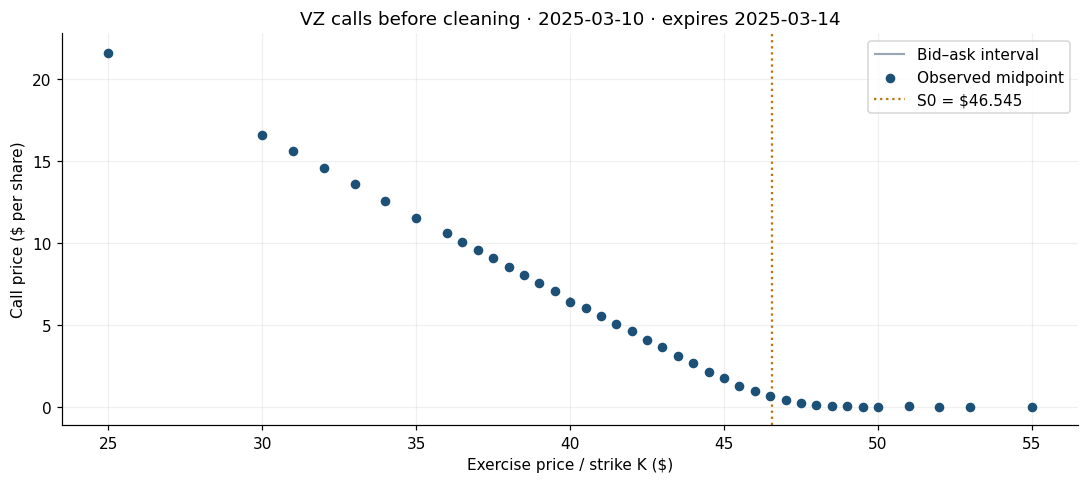

In [6]:
fig_raw, ax = plt.subplots(figsize=(10, 4.5))
plot_raw = chain.loc[np.isfinite(chain[['strike', 'bid', 'ask', 'mid']]).all(axis=1)]
ax.vlines(plot_raw.strike, plot_raw.bid, plot_raw.ask, color='#98a6b6', lw=1.4, label='Bid–ask interval')
ax.scatter(plot_raw.strike, plot_raw.mid, s=28, color='#1d5077', label='Observed midpoint', zorder=3)
ax.axvline(S0, color='#bc741b', ls=':', label=f'S0 = ${S0:.3f}')
ax.set(xlabel='Exercise price / strike K ($)', ylabel='Call price ($ per share)',
       title=f'VZ calls before cleaning · {trade_date.date()} · expires {expiry.date()}')
ax.legend(); fig_raw.tight_layout(); plt.show()

### 6. Apply the rules and retain a full audit

One quote can fail more than one rule, so individual rule counts may add to more
than the number excluded. The audit retains every original strike and all reasons.
Manual exclusions are additional choices you must explain.

In [7]:
flags = quality_flags(chain)
unknown_strikes = set(MANUAL_EXCLUSIONS) - set(chain.strike)
if unknown_strikes:
    raise ValueError(f'Manual exclusion strikes absent from chain: {unknown_strikes}')
if any(not isinstance(reason, str) or not reason.strip() for reason in MANUAL_EXCLUSIONS.values()):
    raise ValueError('Every manual exclusion must have a nonempty reason.')
manual_reason = chain.strike.map(MANUAL_EXCLUSIONS).fillna('')
chain['exclusion_reason'] = flags.apply(lambda row: '; '.join(row.index[row]), axis=1)
for idx in chain.index[manual_reason.ne('')]:
    existing = chain.at[idx, 'exclusion_reason']
    chain.at[idx, 'exclusion_reason'] = (existing + '; ' if existing else '') + 'manual: ' + manual_reason.at[idx]
chain['retained'] = chain.exclusion_reason.eq('')
clean = chain.loc[chain.retained].copy()
excluded = chain.loc[~chain.retained].copy()
if clean.empty:
    raise ValueError('No quotes survived. Review your selected date and thresholds.')
if len(clean) < 8:
    warnings.warn('Few retained strikes: estimating a flexible mixture may be unstable.')

audit_columns = ['source_row', 'strike', 'bid', 'ask', 'mid', 'spread', 'relative_spread',
                 'openInterest', 'prtVolume', 'retained', 'exclusion_reason']
audit_columns = [c for c in audit_columns if c in chain]
audit = chain[audit_columns].copy()
rule_counts = flags.sum().rename('Quotes failing rule').to_frame()
rule_counts.loc['manual exclusion'] = int(manual_reason.ne('').sum())
display(rule_counts)
print(f'Retained {len(clean)} of {len(chain)} calls; excluded {len(excluded)}.')
print('Retained strikes:', clean.strike.tolist())
display(audit.round({'mid': 4, 'spread': 4, 'relative_spread': 4}))

,Quotes failing rule
nonfinite strike/bid/ask,0
nonpositive strike,0
negative bid or ask,0
crossed market (ask < bid),0
zero bid,5
midpoint below minimum,5
absolute spread above limit,4
relative spread above limit,7
manual exclusion,0


Retained 29 of 40 calls; excluded 11.
Retained strikes: [25.0, 30.0, 31.0, 32.0, 33.0, 35.0, 36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 40.5, 41.0, 41.5, 42.0, 42.5, 43.0, 43.5, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 48.5]


,source_row,strike,bid,ask,mid,spread,relative_spread,openInterest,prtVolume,retained,exclusion_reason
3565,3567,25.0,21.45,21.70,21.575,0.25,0.0116,4,2,True,
3567,3569,30.0,16.50,16.70,16.600,0.20,0.0120,0,0,True,
3569,3571,31.0,15.45,15.75,15.600,0.30,0.0192,0,0,True,
3571,3573,32.0,14.45,14.75,14.600,0.30,0.0205,0,0,True,
3573,3575,33.0,13.50,13.70,13.600,0.20,0.0147,0,0,True,
3575,3577,34.0,12.40,12.75,12.575,0.35,0.0278,0,0,False,absolute spread above limit
3577,3579,35.0,11.40,11.70,11.550,0.30,0.0260,13,0,True,
3579,3581,36.0,10.50,10.70,10.600,0.20,0.0189,1,0,True,
3581,3583,36.5,9.90,10.20,10.050,0.30,0.0299,0,0,True,
3583,3585,37.0,9.45,9.75,9.600,0.30,0.0313,0,0,True,


### 7. Compare spreads and visualize the retained observations

Panel 1 shows retained versus excluded prices with quote intervals. Panels 2 and 3
show the absolute and relative spreads against the cutoffs. A small dollar spread
can still be large relative to a cheap out-of-the-money option.

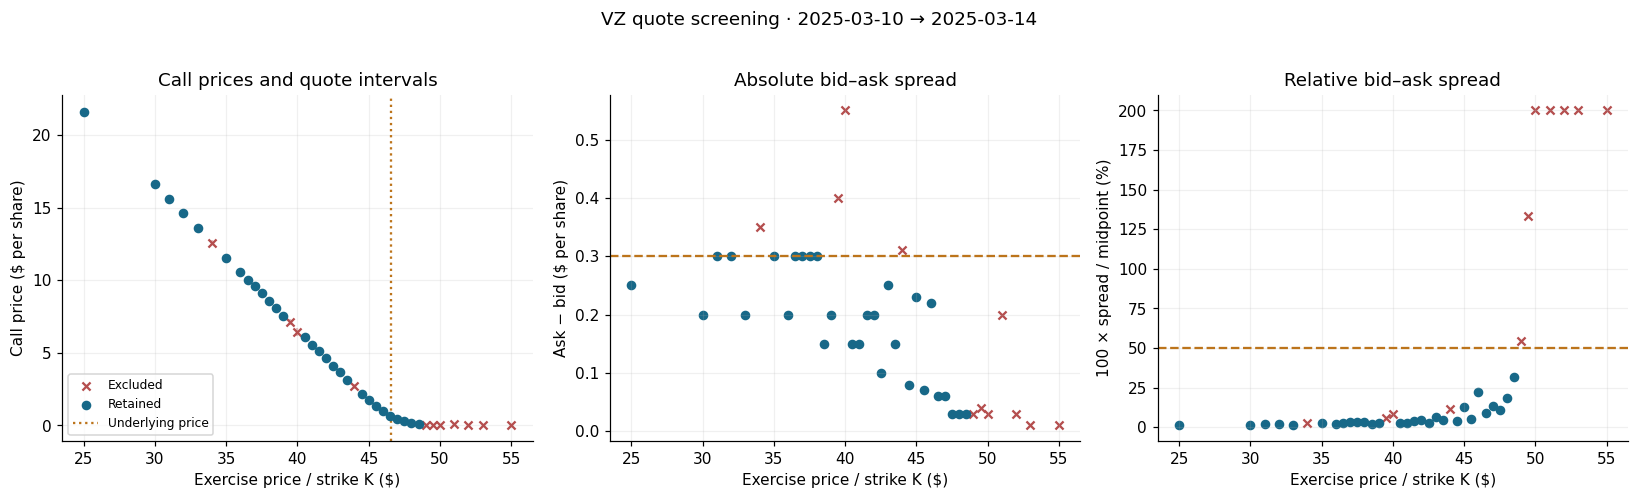

In [8]:
fig_clean, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for keep, label, color, marker in [(False, 'Excluded', '#b44e4e', 'x'),
                                  (True, 'Retained', '#176888', 'o')]:
    d = chain.loc[chain.retained.eq(keep)]
    axes[0].vlines(d.strike, d.bid, d.ask, color=color, alpha=0.35)
    axes[0].scatter(d.strike, d.mid, c=color, marker=marker, s=28, label=label, zorder=3)
    axes[1].scatter(d.strike, d.spread, c=color, marker=marker, s=28)
    axes[2].scatter(d.strike, 100*d.relative_spread, c=color, marker=marker, s=28)
axes[0].axvline(S0, color='#bc741b', ls=':', label='Underlying price')
axes[0].set(title='Call prices and quote intervals', ylabel='Call price ($ per share)')
axes[0].legend(fontsize=8)
axes[1].axhline(MAX_ABS_SPREAD, color='#bc741b', ls='--', label='Absolute cutoff')
axes[1].set(title='Absolute bid–ask spread', ylabel='Ask − bid ($ per share)')
axes[2].axhline(100*MAX_REL_SPREAD, color='#bc741b', ls='--', label='Relative cutoff')
axes[2].set(title='Relative bid–ask spread', ylabel='100 × spread / midpoint (%)')
for ax in axes:
    ax.set_xlabel('Exercise price / strike K ($)')
fig_clean.suptitle(f'VZ quote screening · {trade_date.date()} → {expiry.date()}', y=1.02)
fig_clean.tight_layout(); plt.show()

### 8. Sanity checks — review flags, do not automatically delete them

For a common expiry, calls should generally decrease and be convex in strike.
We check adjacent midpoint slopes using **actual strike spacings** (the grid is
not equally spaced). Midpoints can violate these properties even when trades
inside the quoted intervals could satisfy them, so a flag is not proof of an
executable arbitrage.

For American calls we also flag \(C_{mid}<\max(S_0-K,0)\) and \(C_{mid}>S_0\),
allowing one cent for quote noise. Do not apply a European no-dividend lower
bound to these dividend-paying American contracts without further assumptions.
The selected snapshot and rounding can matter for a short maturity.

In [9]:
K = clean.strike.to_numpy(dtype=float)
C_mid = clean.mid.to_numpy(dtype=float)
slopes = np.diff(C_mid) / np.diff(K)
monotonic_pairs = pd.DataFrame({'K_left': K[:-1], 'K_right': K[1:],
                                'price_change': np.diff(C_mid), 'slope': slopes})
monotonic_flags = monotonic_pairs.loc[monotonic_pairs.price_change.gt(0.01 + EPS)]
convexity_checks = pd.DataFrame({'K_center': K[1:-1],
                                 'left_slope': slopes[:-1], 'right_slope': slopes[1:]})
convexity_checks['slope_change'] = convexity_checks.right_slope - convexity_checks.left_slope
convexity_flags = convexity_checks.loc[convexity_checks.slope_change.lt(-0.01 - EPS)]
bound_flags = clean.loc[(clean.mid < np.maximum(S0-clean.strike, 0)-0.01-EPS) |
                        (clean.mid > S0+0.01+EPS), ['strike', 'mid', 'bid', 'ask']]
print(f'Midpoint increases > $0.01: {len(monotonic_flags)}')
display(monotonic_flags)
print(f'Convexity flags (slope drop > 0.01): {len(convexity_flags)}')
display(convexity_flags)
print(f'American midpoint bound flags, $0.01 tolerance: {len(bound_flags)}')
display(bound_flags)
print(f'Retained below / at / above S0: {(K<S0).sum()} / {(K==S0).sum()} / {(K>S0).sum()}')
print(f'Retained moneyness K/S0: {K.min()/S0:.3f} to {K.max()/S0:.3f}')

Midpoint increases > $0.01: 0


,K_left,K_right,price_change,slope


Convexity flags (slope drop > 0.01): 9


,K_center,left_slope,right_slope,slope_change
3,33.0,-1.000000,-1.025,-0.025000
5,36.0,-0.950000,-1.100,-0.150000
7,37.0,-0.900000,-1.000,-0.100000
8,37.5,-1.000000,-1.100,-0.100000
10,38.5,-0.950000,-1.050,-0.100000
12,40.5,-0.983333,-1.000,-0.016667
15,42.0,-0.900000,-1.100,-0.200000
17,43.0,-0.850000,-1.100,-0.250000
20,45.0,-0.790000,-0.920,-0.130000


American midpoint bound flags, $0.01 tolerance: 0


,strike,mid,bid,ask


Retained below / at / above S0: 25 / 0 / 4
Retained moneyness K/S0: 0.537 to 1.042


### 9. Dividend and model notes to carry into Parts 2–3

- The CSV's `ddiv` and `sdiv` are displayed as raw vendor fields. **A zero `ddiv`
  is not independent confirmation that no ex-dividend event occurs before expiry.**
  Confirm the schedule and field definitions before selecting a dividend assumption.
  Do not interpret `sdiv` automatically as an annual dividend yield.
- Later, European pricing discounts expected terminal payoffs. If you constrain
  the risk-neutral terminal mean using spot and carry, the dividend treatment must
  be explicit. Part 1 does not impose a forward mean or fit a dividend yield.
- These are American options. Early exercise, particularly around ex-dividend
  dates, can affect a European fit. Tight spreads alone do not remove this issue.
- Very short horizons and missing cheap tail quotes limit what the data reveal
  about distribution tails. Deep in-the-money prices mostly reflect intrinsic
  value; many such strikes do not necessarily identify the density well.
- Implied distributions in the later models are risk-neutral pricing distributions;
  their probabilities are not automatically real-world forecasts.

### 10. Prepare the same observations for both later models

`calibration_data` contains the retained calls; `K`, `C_obs`, `S0`, `T`, and `r`
are ready to reuse. The two models should use exactly the same retained rows.
No option model is fitted here. Set `EXPORT_FILES = True` to write the audit,
clean data, candidate table, figures, and assumptions to `part1_outputs/`.

In [10]:
calibration_data = clean[['trade_date', 'expiry', 'strike', 'bid', 'ask', 'mid',
                          'spread', 'relative_spread', 'source_row']].copy()
calibration_data['S0'] = S0
calibration_data['T'] = T
calibration_data['r'] = r
K = calibration_data.strike.to_numpy(dtype=float)
C_obs = calibration_data.mid.to_numpy(dtype=float)

metadata = {
    'source_file': CSV_PATH.name, 'source_sha256': file_sha256,
    'trade_date': str(trade_date.date()), 'expiry': str(expiry.date()),
    'calendar_days': calendar_days, 'S0': S0, 'spot_source': '(uBid + uAsk) / 2',
    'T': T, 'time_source': TIME_SOURCE, 'T_calendar': T_calendar, 'T_vendor': T_vendor,
    'r': r, 'rate_note': RATE_NOTE, 'rate_override': RATE_OVERRIDE,
    'dividend_assumption': 'Unresolved: verify schedule and CSV field conventions before fitting',
    'price_source': '(bidPrc + askPrc) / 2',
    'min_mid': MIN_MID, 'max_absolute_spread': MAX_ABS_SPREAD,
    'max_relative_spread': MAX_REL_SPREAD,
    'manual_exclusions': {str(k): v for k, v in MANUAL_EXCLUSIONS.items()},
    'available_calls': len(chain), 'retained_calls': len(clean),
    'strike_min': float(K.min()), 'strike_max': float(K.max()),
}
assert calibration_data.strike.is_unique
assert np.isfinite(calibration_data[['strike','bid','ask','mid','S0','T','r']]).all().all()
assert (calibration_data.ask >= calibration_data.bid - EPS).all()
display(calibration_data.round({col: 6 for col in calibration_data.select_dtypes(include='number').columns}))
if EXPORT_FILES:
    out = Path('part1_outputs')
    out.mkdir(exist_ok=True)
    calibration_data.to_csv(out / 'VZ_part1_clean_calls.csv', index=False)
    audit.to_csv(out / 'VZ_part1_quote_audit.csv', index=False)
    candidates.to_csv(out / 'VZ_part1_candidates.csv', index=False)
    (out / 'VZ_part1_inputs.json').write_text(json.dumps(metadata, indent=2))
    fig_raw.savefig(out / 'VZ_part1_observed_calls.png', dpi=180, bbox_inches='tight')
    fig_clean.savefig(out / 'VZ_part1_screening.png', dpi=180, bbox_inches='tight')
    print('Exported tables, assumptions and plots to', out.resolve())
else:
    print('Exports disabled; all tables and plots remain visible in this notebook.')

,trade_date,expiry,strike,bid,ask,mid,spread,relative_spread,source_row,S0,T,r
3565,2025-03-10,2025-03-14,25.0,21.45,21.70,21.575,0.25,0.011587,3567,46.545,0.010959,0.044504
3567,2025-03-10,2025-03-14,30.0,16.50,16.70,16.600,0.20,0.012048,3569,46.545,0.010959,0.044504
3569,2025-03-10,2025-03-14,31.0,15.45,15.75,15.600,0.30,0.019231,3571,46.545,0.010959,0.044504
3571,2025-03-10,2025-03-14,32.0,14.45,14.75,14.600,0.30,0.020548,3573,46.545,0.010959,0.044504
3573,2025-03-10,2025-03-14,33.0,13.50,13.70,13.600,0.20,0.014706,3575,46.545,0.010959,0.044504
3577,2025-03-10,2025-03-14,35.0,11.40,11.70,11.550,0.30,0.025974,3579,46.545,0.010959,0.044504
3579,2025-03-10,2025-03-14,36.0,10.50,10.70,10.600,0.20,0.018868,3581,46.545,0.010959,0.044504
3581,2025-03-10,2025-03-14,36.5,9.90,10.20,10.050,0.30,0.029851,3583,46.545,0.010959,0.044504
3583,2025-03-10,2025-03-14,37.0,9.45,9.75,9.600,0.30,0.031250,3585,46.545,0.010959,0.044504
3585,2025-03-10,2025-03-14,37.5,8.95,9.25,9.100,0.30,0.032967,3587,46.545,0.010959,0.044504


Exported tables, assumptions and plots to C:\Users\samla\OneDrive\Documentos 1\Documentos\ELAB\Maestría\NYU\Semester 1\Valuation for Financial Engineering\Homework\Mini Project 5\miniProject5\part1_outputs


---
## Part 2 — Estimate the lognormal terminal distribution

### 2.1 What do the two parameters mean?

Write the assignment's terminal distribution as

$$\ln S_T=\mu+\sigma Z,\qquad Z\sim N(0,1),\quad\sigma>0.$$

| Symbol | Meaning | Units / distinction |
|---|---|---|
| $\mu$ | Mean of **log terminal price** | Not the mean stock price; not an annual drift. |
| $\sigma$ | Standard deviation of **log terminal price** | Terminal-horizon quantity; not annual volatility. |
| $F=E^Q[S_T]$ | Mean terminal stock price | Dollars per share; equals $e^{\mu+\sigma^2/2}$. |
| $v=\sigma/\sqrt{T}$ | BSM-equivalent annual volatility | Useful conversion, conditional on chosen $T$. |
| $\Phi$, $\varphi$ | Standard normal CDF and PDF | `scipy.stats.norm.cdf` and `.pdf`. |

For example, under a BSM model with a continuous dividend yield $q$,
$\mu=\ln S_0+(r-q-v^2/2)T$ and $\sigma=v\sqrt{T}$.
We do **not** multiply the assignment's $\sigma$ by $\sqrt T$ again in the terminal
pricing formula. All probabilities below are under an assumed pricing measure,
not estimates of real-world frequencies.

### 2.2 Derive the expected payoff, then discount it

For strike $K>0$, the call pays $(S_T-K)^+$. Split its expectation:

$$E^Q[(S_T-K)^+]
=E^Q[S_T\mathbf1_{\{S_T>K\}}]-K\,Q(S_T>K).$$

**First term to evaluate: the exercise probability.** Since $S_T=e^{\mu+\sigma Z}$,

$$S_T>K\iff Z>a,\qquad a=\frac{\ln K-\mu}{\sigma}.$$

Thus, setting $d_2=(\mu-\ln K)/\sigma=-a$,

$$Q(S_T>K)=1-\Phi(a)=\Phi(d_2).$$

**Second term: the stock price weighted by the exercise event.** It is not simply
$E^Q[S_T]\times Q(S_T>K)$, because larger stock prices are more likely to be in
the exercise event:

$$E^Q[S_T\mathbf1_{\{S_T>K\}}]
=\int_a^\infty e^{\mu+\sigma z}\varphi(z)\,dz.$$

Complete the square in the exponent:

$$-\frac{z^2}{2}+\sigma z
=-\frac{(z-\sigma)^2}{2}+\frac{\sigma^2}{2}.$$

Therefore

$$\begin{aligned}
E^Q[S_T\mathbf1_{\{S_T>K\}}]
&=e^{\mu+\sigma^2/2}\int_a^\infty\varphi(z-\sigma)\,dz\\
&=e^{\mu+\sigma^2/2}\Phi(\sigma-a)
=e^{\mu+\sigma^2/2}\Phi(d_1),
\end{aligned}$$

where $d_1=d_2+\sigma$. Combining the two terms gives the **undiscounted expected payoff**:

$$\boxed{E^Q[(S_T-K)^+]
=e^{\mu+\sigma^2/2}\Phi(d_1)-K\Phi(d_2).}$$

Under deterministic interest rates, the **European price today** is

$$\boxed{C(K;\mu,\sigma)=e^{-rT}
\left[e^{\mu+\sigma^2/2}\Phi(d_1)-K\Phi(d_2)\right].}$$

The expectation and the current price are different quantities: only the price
includes $e^{-rT}$. Equivalently, with $F=e^{\mu+\sigma^2/2}$,

$$d_2=\frac{\ln(F/K)-\sigma^2/2}{\sigma},\qquad
C=e^{-rT}\{F\Phi(d_2+\sigma)-K\Phi(d_2)\}.$$

This last form is convenient for optimization: estimate the positive quantities
$F$ and $\sigma$, then recover $\mu=\ln F-\sigma^2/2$.

### 2.3 Economic choice: should the expected terminal price be free?

**Main result — enforce stock carry.** For a stock with no dividend entitlement
lost before expiration, frictionless risk-neutral pricing requires

$$F=E^Q[S_T]=S_0e^{rT}.$$

With a present value $PV(D)$ of dividends over the option's horizon, the usual
discrete-dividend carry approximation is $F=(S_0-PV(D))e^{rT}$; with a continuous
yield it is $F=S_0e^{(r-q)T}$. We use the discrete-event view for this short horizon.
Enforcing this relationship means that $\sigma$ is the only free calibration
parameter, and $\mu$ is determined by $\mu=\ln F-\sigma^2/2$. Both terminal
distribution parameters are still reported.

**Diagnostic — fit both terminal parameters freely.** We also fit $(F,\sigma)$
without imposing carry, which is equivalent to fitting $(\mu,\sigma)$. It may
reduce pricing errors, but if its mean differs from the carry-implied forward,
it is an approximate call-price fit rather than an exactly consistent
risk-neutral model of both the stock and the calls. Do not interpret that gap
as an estimate of investors' expected stock return or a dividend yield.

**Rates and time:** retain Part 1's annual `r` and `T` convention. Use continuous
discounting, treating the CSV rate convention as a working assumption. Changing
`T` affects the annual volatility conversion; terminal $\sigma$ is the directly
estimated dispersion. No historical stock-growth estimate is introduced.

**Dividends for the selected March example:** Verizon's official history lists
ex-dividend dates of January 10 and April 10, 2025, so no ex-dividend event falls
between March 10 and March 14. Accordingly $PV(D)=0$ for this horizon. This does
not mean Verizon pays no dividends over the year. The February 28, 2025 release
had already announced the next dividend before the selected trading date.

Sources (checked November 15, 2026):
[Verizon dividend history](https://www.verizon.com/about/investors/dividend-history)
and [February 28, 2025 dividend announcement](https://www.verizon.com/about/news/verizon-declares-quarterly-dividend-february-28).

In [11]:
import scipy
from scipy.optimize import least_squares
from scipy.stats import norm, lognorm
from scipy.integrate import quad

# 'forward' is the main economically constrained result.
# 'free' reports the unrestricted two-terminal-parameter fit instead.
MEAN_TREATMENT = 'forward'
PV_DIVIDENDS_OVERRIDE = None  # Dollars per share; document a source if supplied.
DIVIDEND_OVERRIDE_NOTE = ''

# Known 2025 ex-dividend dates, transcribed from the issuer's history.
# Offline record: no internet access is needed to rerun this notebook.
ex_dividend_dates_2025 = pd.to_datetime(['2025-01-10', '2025-04-10',
                                       '2025-07-10', '2025-10-10'])
ex_events = ex_dividend_dates_2025[(ex_dividend_dates_2025 > trade_date) &
                                 (ex_dividend_dates_2025 <= expiry)]
if PV_DIVIDENDS_OVERRIDE is not None:
    if not DIVIDEND_OVERRIDE_NOTE.strip():
        raise ValueError('Document the source and timing used for the dividend PV override.')
    pv_dividends = float(PV_DIVIDENDS_OVERRIDE)
elif (trade_date >= pd.Timestamp('2025-01-01') and expiry <= pd.Timestamp('2025-12-31')
      and len(ex_events) == 0):
    pv_dividends = 0.0
else:
    raise ValueError('Review dividends for the new horizon, then set the PV override and its source note. '
                     f'Known ex-dividend events in this horizon: {ex_events.tolist()}')
if not np.isfinite(pv_dividends) or not 0 <= pv_dividends < S0:
    raise ValueError('Dividend PV must be finite, nonnegative and less than spot.')
if MEAN_TREATMENT not in {'forward', 'free'}:
    raise ValueError("MEAN_TREATMENT must be 'forward' or 'free'.")

# Fresh arrays are taken from the retained Part 1 table, without new filtering.
K = calibration_data.strike.to_numpy(dtype=float)
C_obs = calibration_data.mid.to_numpy(dtype=float)
bid_obs = calibration_data.bid.to_numpy(dtype=float)
ask_obs = calibration_data.ask.to_numpy(dtype=float)
if len(K) < 3 or np.any(K <= 0):
    raise ValueError('Need at least three positive, distinct strikes for this calibration and its diagnostics.')
discount = np.exp(-r*T)
F_carry = (S0-pv_dividends)*np.exp(r*T)
print('SciPy:', scipy.__version__)
print(f'{len(K)} retained calls | {trade_date.date()} → {expiry.date()} | S0=${S0:.3f}')
print(f'r={r:.8f}, T={T:.8f}, discount={discount:.8f}')
print(f'Dividend PV=${pv_dividends:.6f}; carry-implied forward=${F_carry:.6f}')

SciPy: 1.16.3
29 retained calls | 2025-03-10 → 2025-03-14 | S0=$46.545
r=0.04450360, T=0.01095890, discount=0.99951241
Dividend PV=$0.000000; carry-implied forward=$46.567706


### 2.4 Define the pricing function and the calibration objective

For retained midquotes $C_i^{obs}$, minimize **unweighted squared dollar errors**:

$$\min_{\mu,\,\sigma>0}\sum_i
\left[C(K_i;\mu,\sigma)-C_i^{obs}\right]^2.$$

For the main fit impose $e^{\mu+\sigma^2/2}=F_{carry}$; for the diagnostic leave
both parameters free. Each quote has the same weight in dollar space. Relative
errors would heavily weight very cheap options; spread-weighted errors would
answer a different fitting question. We do not claim unweighted least squares
is the unique correct choice.

The code optimizes logarithms to ensure positive $F$ and $\sigma$. Broad numerical
bounds are safeguards, not estimated economic facts; boundary hits are checked.
The routine uses analytic derivatives, and a failed optimization is an error.

In [12]:
def lognormal_call_from_mean(strikes, F, sigma, rate, maturity):
    """European prices from terminal mean F and terminal log-SD sigma.

    sigma already describes the full terminal horizon. No extra sqrt(T) here.
    """
    strikes = np.asarray(strikes, dtype=float)
    if np.any(strikes <= 0) or F <= 0 or sigma <= 0:
        raise ValueError('Strikes, F and terminal sigma must be positive.')
    d2 = (np.log(F/strikes)-0.5*sigma**2)/sigma
    d1 = d2+sigma
    return np.exp(-rate*maturity)*(F*norm.cdf(d1)-strikes*norm.cdf(d2))

def lognormal_call(strikes, mu, sigma, rate, maturity):
    """Same pricing function in the assignment's (mu, sigma) notation."""
    F = np.exp(mu+0.5*sigma**2)
    return lognormal_call_from_mean(strikes, F, sigma, rate, maturity)

SIGMA_BOUNDS = (1e-5, 2.0)  # Terminal log standard deviation, not annualized.
F_BOUNDS = (0.1*S0, 10*S0)  # Only used in the unrestricted diagnostic.
sigma_initial = np.clip(0.25*np.sqrt(T), 1e-4, 1.0)

def fit_lognormal(mean_treatment):
    if mean_treatment == 'forward':
        x0 = [np.log(sigma_initial)]
        bounds = ([np.log(SIGMA_BOUNDS[0])], [np.log(SIGMA_BOUNDS[1])])
        def unpack(x):
            return F_carry, float(np.exp(x[0]))
    elif mean_treatment == 'free':
        x0 = [np.log(F_carry), np.log(sigma_initial)]
        bounds = (np.log([F_BOUNDS[0], SIGMA_BOUNDS[0]]),
                  np.log([F_BOUNDS[1], SIGMA_BOUNDS[1]]))
        def unpack(x):
            return float(np.exp(x[0])), float(np.exp(x[1]))
    else:
        raise ValueError('Unknown mean treatment.')

    def residual(x):
        F, sigma = unpack(x)
        return lognormal_call_from_mean(K, F, sigma, r, T)-C_obs

    def jacobian(x):
        F, sigma = unpack(x)
        d1 = (np.log(F/K)+0.5*sigma**2)/sigma
        # Derivatives of price w.r.t. log(F) and log(sigma).
        d_logF = discount*F*norm.cdf(d1)
        d_logsigma = discount*F*norm.pdf(d1)*sigma
        return (d_logsigma[:, None] if mean_treatment == 'forward'
                else np.column_stack([d_logF, d_logsigma]))

    result = least_squares(residual, x0, jac=jacobian, bounds=bounds,
                           loss='linear', ftol=1e-12, xtol=1e-12, gtol=1e-12,
                           max_nfev=3000)
    if not result.success or not np.isfinite(result.fun).all():
        raise RuntimeError(f'Calibration failed: {result.message}')
    if np.any(result.active_mask != 0):
        warnings.warn('An optimization bound is active. Review bounds and identification.')
    F, sigma = unpack(result.x)
    mu = np.log(F)-0.5*sigma**2
    fitted = lognormal_call(K, mu, sigma, r, T)
    sd = F*np.sqrt(np.expm1(sigma**2))
    return {'mean_treatment': mean_treatment, 'mu': float(mu), 'sigma': sigma,
            'mean': F, 'std': float(sd),
            'p_below_spot': float(norm.cdf((np.log(S0)-mu)/sigma)),
            'annual_vol_equivalent': float(sigma/np.sqrt(T)),
            'rmse': float(np.sqrt(np.mean((fitted-C_obs)**2))),
            'fitted': fitted, 'optimizer': result}

fits = {mode: fit_lognormal(mode) for mode in ['forward', 'free']}
chosen = fits[MEAN_TREATMENT]
mu_hat, sigma_hat = chosen['mu'], chosen['sigma']
C_fitted = chosen['fitted']
comparison_rows = []
for label, fit in fits.items():
    comparison_rows.append({'Fit': label, 'Free parameters': 1 if label == 'forward' else 2,
        'mu: terminal log mean': fit['mu'], 'sigma: terminal log SD': fit['sigma'],
        'Mean ST ($)': fit['mean'], 'SD ST ($)': fit['std'],
        'P(ST < S0)': fit['p_below_spot'], 'RMSE ($/share)': fit['rmse'],
        'Mean minus carry F ($)': fit['mean']-F_carry})
fit_comparison = pd.DataFrame(comparison_rows).set_index('Fit')
display(fit_comparison.round(8))
print('Selected result:', MEAN_TREATMENT)
print('Optimizer:', chosen['optimizer'].message)
print(f'BSM-equivalent annual volatility: {100*chosen["annual_vol_equivalent"]:.3f}%')
print('The free fit is a pricing diagnostic; a lower RMSE does not remove its carry inconsistency.')


,Free parameters,mu: terminal log mean,sigma: terminal log SD,Mean ST ($),SD ST ($),P(ST < S0),RMSE ($/share),Mean minus carry F ($)
Fit,,,,,,,,
forward,1,3.840276,0.035521,46.567706,1.654633,0.501608,0.038296,0.00000
free,2,3.840979,0.034346,46.598526,1.600928,0.493501,0.028275,0.03082


Selected result: forward
Optimizer: `ftol` termination condition is satisfied.
BSM-equivalent annual volatility: 33.931%
The free fit is a pricing diagnostic; a lower RMSE does not remove its carry inconsistency.


### 2.5 Check how well the model reproduces the quotes

RMSE is $\sqrt{n^{-1}\sum_i(C_i^{model}-C_i^{obs})^2}$ in dollars per share.
Also compare the model with the entire bid–ask interval: a midpoint error can
be economically small when it lies inside that interval. The right price panel
zooms near the stock price, where option curvature is easiest to see.

,strike,bid,ask,mid,spread,model_call,error_model_minus_mid,inside_bid_ask,distance_outside_quote
3565,25.0,21.45,21.70,21.575,0.25,21.557190,-0.017810,True,0.000000
3567,30.0,16.50,16.70,16.600,0.20,16.559628,-0.040372,True,0.000000
3569,31.0,15.45,15.75,15.600,0.30,15.560115,-0.039885,True,0.000000
3571,32.0,14.45,14.75,14.600,0.30,14.560603,-0.039397,True,0.000000
3573,33.0,13.50,13.70,13.600,0.20,13.561091,-0.038909,True,0.000000
3577,35.0,11.40,11.70,11.550,0.30,11.562066,0.012066,True,0.000000
3579,36.0,10.50,10.70,10.600,0.20,10.562553,-0.037447,True,0.000000
3581,36.5,9.90,10.20,10.050,0.30,10.062797,0.012797,True,0.000000
3583,37.0,9.45,9.75,9.600,0.30,9.563041,-0.036959,True,0.000000
3585,37.5,8.95,9.25,9.100,0.30,9.063285,-0.036715,True,0.000000


RMSE=$0.038296/share; 27/29 prices inside bid–ask.


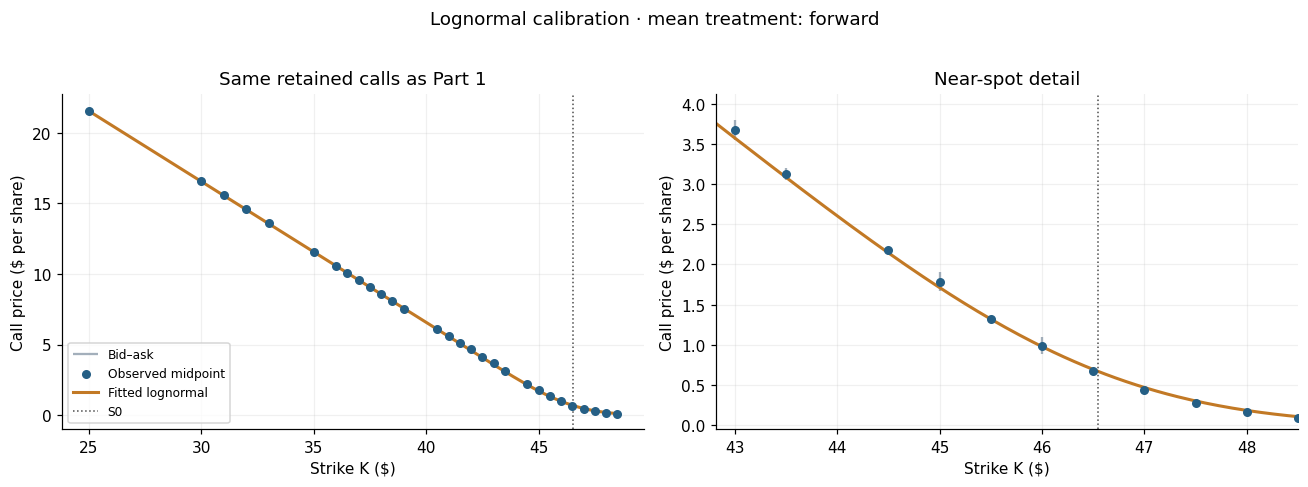

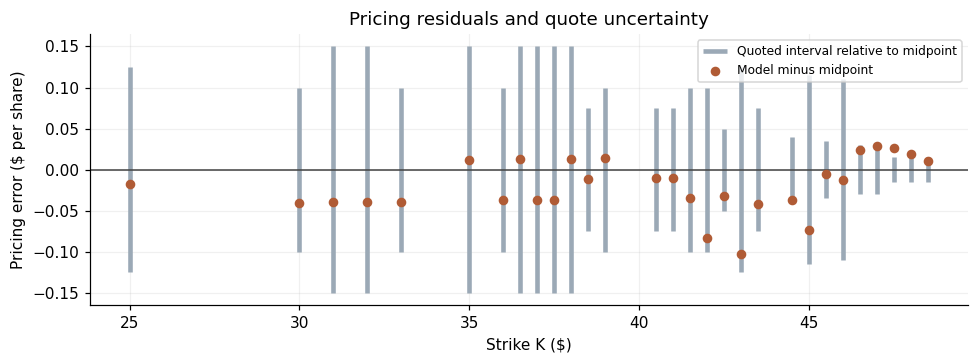

In [13]:
pricing_table = calibration_data[['strike', 'bid', 'ask', 'mid', 'spread']].copy()
pricing_table['model_call'] = C_fitted
pricing_table['error_model_minus_mid'] = C_fitted-C_obs
pricing_table['inside_bid_ask'] = ((C_fitted >= bid_obs-EPS) & (C_fitted <= ask_obs+EPS))
pricing_table['distance_outside_quote'] = np.maximum.reduce(
    [bid_obs-C_fitted, C_fitted-ask_obs, np.zeros(len(K))])
display(pricing_table.round(6))
inside_count = int(pricing_table.inside_bid_ask.sum())
print(f'RMSE=${chosen["rmse"]:.6f}/share; {inside_count}/{len(K)} prices inside bid–ask.')

fig_fit, axes = plt.subplots(1, 2, figsize=(12, 4.3))
K_curve = np.linspace(K.min(), K.max(), 700)
C_curve = lognormal_call(K_curve, mu_hat, sigma_hat, r, T)
for ax in axes:
    ax.vlines(K, bid_obs, ask_obs, color='#8c9baa', alpha=0.8, label='Bid–ask')
    ax.scatter(K, C_obs, s=24, color='#255f85', label='Observed midpoint', zorder=3)
    ax.plot(K_curve, C_curve, color='#c27925', lw=2, label='Fitted lognormal')
    ax.axvline(S0, color='#4d4d4d', ls=':', lw=1, label='S0')
    ax.set(xlabel='Strike K ($)', ylabel='Call price ($ per share)')
axes[0].set_title('Same retained calls as Part 1')
zoom_lo, zoom_hi = max(K.min(), 0.92*S0), min(K.max(), 1.06*S0)
axes[1].set(xlim=(zoom_lo, zoom_hi),
            ylim=(-0.05, 1.1*max(lognormal_call(zoom_lo, mu_hat, sigma_hat, r, T), 0.1)),
            title='Near-spot detail')
axes[0].legend(fontsize=8)
fig_fit.suptitle(f'Lognormal calibration · mean treatment: {MEAN_TREATMENT}', y=1.02)
fig_fit.tight_layout(); plt.show()

fig_residual, ax = plt.subplots(figsize=(9, 3.4))
ax.vlines(K, bid_obs-C_obs, ask_obs-C_obs, color='#9ba9b6', lw=3, label='Quoted interval relative to midpoint')
ax.scatter(K, C_fitted-C_obs, s=28, color='#b05b35', label='Model minus midpoint', zorder=3)
ax.axhline(0, color='#424242', lw=1)
ax.set(xlabel='Strike K ($)', ylabel='Pricing error ($ per share)', title='Pricing residuals and quote uncertainty')
ax.legend(fontsize=8); fig_residual.tight_layout(); plt.show()

### 2.6 Recover the implied density and requested statistics

For $s>0$,

$$f(s)=\frac{1}{s\sigma\sqrt{2\pi}}
\exp\!\left[-\frac{(\ln s-\mu)^2}{2\sigma^2}\right].$$

The lognormal moments follow from $E[e^{tZ}]=e^{t^2/2}$:

$$E[S_T]=e^{\mu+\sigma^2/2},\qquad
\operatorname{Var}(S_T)=(e^{\sigma^2}-1)e^{2\mu+\sigma^2}.$$

Hence

$$\boxed{\operatorname{SD}(S_T)
=e^{\mu+\sigma^2/2}\sqrt{e^{\sigma^2}-1}},\qquad
\boxed{Q(S_T<S_0)=\Phi\!\left(\frac{\ln S_0-\mu}{\sigma}\right)}.$$

The probability is an **area under the density**, not the height $f(S_0)$.
The price standard deviation is measured in dollars; it differs from both
terminal log-price standard deviation $\sigma$ and annual volatility $v$.

,Measure,Value
0,Selected mean treatment,forward
1,Terminal log mean mu,3.84027644
2,Terminal log SD sigma,0.03552056
3,Mean terminal stock price ($),46.567706
4,SD terminal stock price ($),1.654633
5,Probability ST < S0,50.1608%
6,Pricing RMSE ($/share),0.038296
7,BSM-equivalent annual volatility,33.9310%


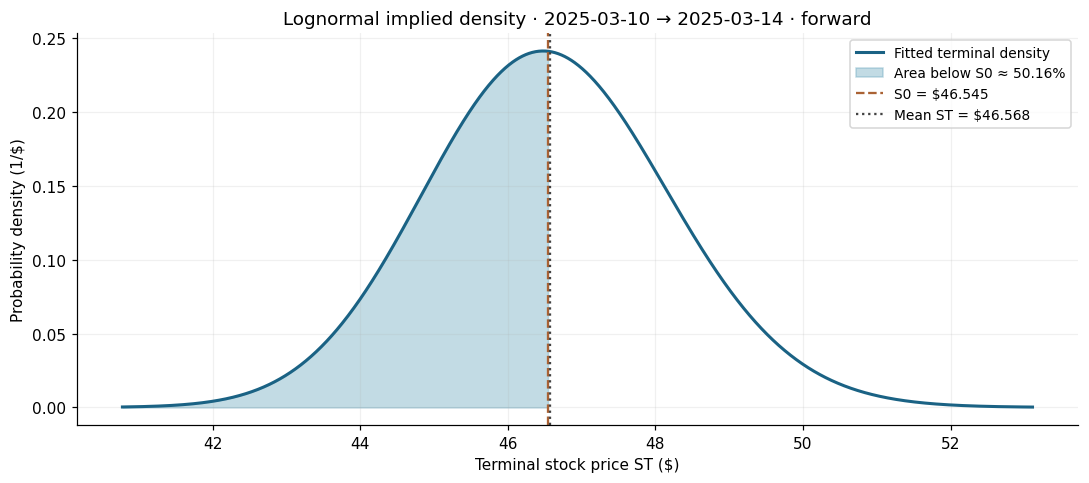

The plot shows the central 99.98% of the fitted distribution; probabilities use the full CDF.


In [14]:
terminal_lognormal = lognorm(s=sigma_hat, scale=np.exp(mu_hat), loc=0)
mean_ST = float(np.exp(mu_hat+0.5*sigma_hat**2))
sd_ST = float(mean_ST*np.sqrt(np.expm1(sigma_hat**2)))
p_below_S0 = float(norm.cdf((np.log(S0)-mu_hat)/sigma_hat))
summary = pd.DataFrame({
    'Measure': ['Selected mean treatment', 'Terminal log mean mu', 'Terminal log SD sigma',
                'Mean terminal stock price ($)', 'SD terminal stock price ($)',
                'Probability ST < S0', 'Pricing RMSE ($/share)',
                'BSM-equivalent annual volatility'],
    'Value': [MEAN_TREATMENT, f'{mu_hat:.8f}', f'{sigma_hat:.8f}',
              f'{mean_ST:.6f}', f'{sd_ST:.6f}', f'{100*p_below_S0:.4f}%',
              f'{chosen["rmse"]:.6f}', f'{100*sigma_hat/np.sqrt(T):.4f}%']})
display(summary)

left = min(float(terminal_lognormal.ppf(0.0001)), S0)
right = max(float(terminal_lognormal.ppf(0.9999)), S0)
s_grid = np.sort(np.unique(np.r_[np.linspace(left, right, 1400), S0]))
density = terminal_lognormal.pdf(s_grid)
fig_density, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(s_grid, density, color='#1a6284', lw=2, label='Fitted terminal density')
ax.fill_between(s_grid, density, where=(s_grid <= S0), color='#68a6bd', alpha=0.4,
                label=f'Area below S0 ≈ {100*p_below_S0:.2f}%')
ax.axvline(S0, color='#aa6234', ls='--', label=f'S0 = ${S0:.3f}')
ax.axvline(mean_ST, color='#424242', ls=':', label=f'Mean ST = ${mean_ST:.3f}')
ax.set(xlabel='Terminal stock price ST ($)', ylabel='Probability density (1/$)',
       title=f'Lognormal implied density · {trade_date.date()} → {expiry.date()} · {MEAN_TREATMENT}')
ax.legend(fontsize=9); fig_density.tight_layout(); plt.show()
print('The plot shows the central 99.98% of the fitted distribution; probabilities use the full CDF.')

### 2.7 Numerical validation

These checks independently compare the closed form with numerical integration,
and verify that imposing carry gives the usual BSM formula. The density check
integrates across log prices to avoid a quadrature routine missing a narrow
short-horizon density. These are calculation checks, not evidence that the
lognormal family is the true distribution.

In [15]:
# Check closed-form expected payoff against quadrature over a standard normal.
validation_rows = []
for strike in [float(K.min()), float(K[np.argmin(abs(K-S0))]), float(K.max())]:
    a = (np.log(strike)-mu_hat)/sigma_hat
    lower_z = max(a, -12.0)
    numeric_payoff = (quad(lambda z: (np.exp(mu_hat+sigma_hat*z)-strike)*norm.pdf(z),
                           lower_z, 12.0, epsabs=1e-10, epsrel=1e-10)[0]
                       if lower_z < 12 else 0.0)
    analytic_payoff = float(lognormal_call(strike, mu_hat, sigma_hat, r, T)/discount)
    np.testing.assert_allclose(analytic_payoff, numeric_payoff, rtol=1e-7, atol=1e-8)
    validation_rows.append({'K': strike, 'Closed-form expected payoff': analytic_payoff,
                            'Integrated expected payoff': numeric_payoff,
                            'Difference': analytic_payoff-numeric_payoff})
display(pd.DataFrame(validation_rows).round(10))

mass = quad(lambda y: float(terminal_lognormal.pdf(np.exp(y))*np.exp(y)),
            mu_hat-12*sigma_hat, mu_hat+12*sigma_hat, epsabs=1e-10)[0]
np.testing.assert_allclose(mass, 1.0, atol=1e-9)
np.testing.assert_allclose(terminal_lognormal.mean(), mean_ST, rtol=1e-12)
np.testing.assert_allclose(terminal_lognormal.std(), sd_ST, rtol=1e-12)
np.testing.assert_allclose(terminal_lognormal.cdf(S0), p_below_S0, rtol=1e-12)

fwd_fit = fits['forward']
v_check = fwd_fit['sigma']/np.sqrt(T)
prepaid_spot = S0-pv_dividends
d1_bs = (np.log(prepaid_spot/K)+(r+0.5*v_check**2)*T)/(v_check*np.sqrt(T))
d2_bs = d1_bs-v_check*np.sqrt(T)
bs_prices = prepaid_spot*norm.cdf(d1_bs)-K*discount*norm.cdf(d2_bs)
np.testing.assert_allclose(bs_prices, fwd_fit['fitted'], atol=1e-10)
assert 0 <= p_below_S0 <= 1 and sigma_hat > 0
print(f'PASS: density mass={mass:.12f}, moments/CDF agree, payoff integral and BSM identity agree.')

,K,Closed-form expected payoff,Integrated expected payoff,Difference
0,25.0,21.567706,21.567706,-0.0
1,46.5,0.693786,0.693786,0.0
2,48.5,0.105972,0.105972,-0.0


PASS: density mass=1.000000000000, moments/CDF agree, payoff integral and BSM identity agree.


## Part 3 — Estimating a Mixture of Normals (30 points)

Now assume the terminal stock price follows a mixture of two normal distributions:

$$
f(S_T)=w\phi(S_T;\mu_1,\sigma_1)
+(1-w)\phi(S_T;\mu_2,\sigma_2).
$$

--- 

First, we need to upload the data for calls saved in part 1 

In [16]:
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / 'part1_outputs'

processed_calls = pd.read_csv(PROCESSED_DIR / 'VZ_part1_clean_calls.csv')

processed_calls.head(10)

,trade_date,expiry,strike,bid,ask,mid,spread,relative_spread,source_row,S0,T,r
0,2025-03-10,2025-03-14,25.0,21.45,21.70,21.575,0.25,0.011587,3567,46.545,0.010959,0.044504
1,2025-03-10,2025-03-14,30.0,16.50,16.70,16.600,0.20,0.012048,3569,46.545,0.010959,0.044504
2,2025-03-10,2025-03-14,31.0,15.45,15.75,15.600,0.30,0.019231,3571,46.545,0.010959,0.044504
3,2025-03-10,2025-03-14,32.0,14.45,14.75,14.600,0.30,0.020548,3573,46.545,0.010959,0.044504
4,2025-03-10,2025-03-14,33.0,13.50,13.70,13.600,0.20,0.014706,3575,46.545,0.010959,0.044504
5,2025-03-10,2025-03-14,35.0,11.40,11.70,11.550,0.30,0.025974,3579,46.545,0.010959,0.044504
6,2025-03-10,2025-03-14,36.0,10.50,10.70,10.600,0.20,0.018868,3581,46.545,0.010959,0.044504
7,2025-03-10,2025-03-14,36.5,9.90,10.20,10.050,0.30,0.029851,3583,46.545,0.010959,0.044504
8,2025-03-10,2025-03-14,37.0,9.45,9.75,9.600,0.30,0.031250,3585,46.545,0.010959,0.044504
9,2025-03-10,2025-03-14,37.5,8.95,9.25,9.100,0.30,0.032967,3587,46.545,0.010959,0.044504


Now we define by defining the required parameters: 

- $S_t$
- $\mu_1$
- $\sigma_1$
- $\mu_2$
- $\sigma_2$
- $w$

In [17]:
K = processed_calls['strike'].to_numpy()
C_obs = processed_calls['mid'].to_numpy()

S_0 = processed_calls['S0'].iloc[0]
T = processed_calls['T'].iloc[0]
r = processed_calls['r'].iloc[0]

We will part from the Bachelier Formula

$$
C_i = \Beta(\mu_i - K) \Phi(d) + \Beta \sigma \sqrt{T} \phi(d)  \\
\text{where } \\
d = \frac{\mu_i - K}{\sigma\sqrt{T}} \\
and \\
\Beta = e^{-rT}
$$

Lets first plot the distribution of call prices realtive to the strike price

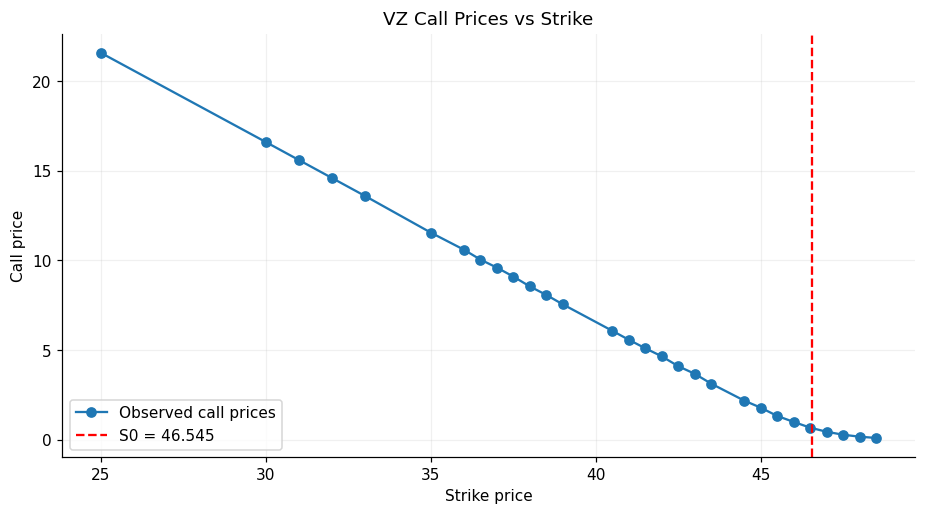

In [18]:
order = np.argsort(K)
K = K[order]
C_obs = C_obs[order]

plt.figure(figsize=(10, 5))
plt.plot(K, C_obs, "o-", label="Observed call prices")
plt.axvline(S_0, color="red", linestyle="--", label=f"S0 = {S_0:.3f}")
plt.xlabel("Strike price")
plt.ylabel("Call price")
plt.title("VZ Call Prices vs Strike")
plt.legend()
plt.grid(True)
plt.show()

The a raw density approximated by the gradient of the call relative to the strike price and the second derivative.

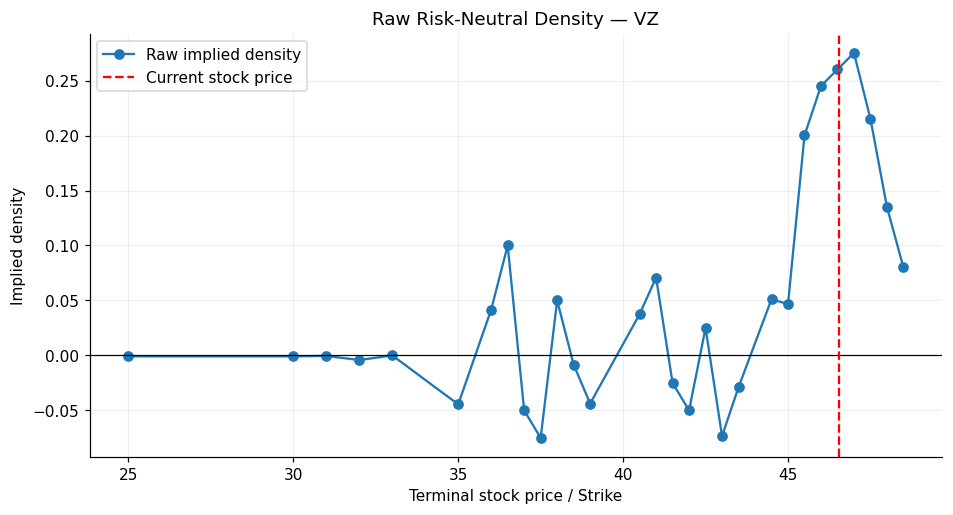

In [19]:
# First derivative with respect to strike
dC_dK = np.gradient(C_obs, K)

# Second derivative
d2C_dK2 = np.gradient(dC_dK, K)

# Breeden-Litzenberger density estimate
density = np.exp(r * T) * d2C_dK2

plt.figure(figsize=(10, 5))
plt.plot(K, density, "o-", label="Raw implied density")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(S_0, color="red", linestyle="--", label="Current stock price")
plt.xlabel("Terminal stock price / Strike")
plt.ylabel("Implied density")
plt.title("Raw Risk-Neutral Density — VZ")
plt.legend()
plt.grid(True)
plt.show()

Let us do the model first by computing a function for the bachelier call: ``bach_call`` and the mixture call ``mix_call``. 
for the mix_call fucntion we are using the parameter $\theta$ such thta $\theta = (\mu_1, \sigma_1, \mu_2, \sigma_2, w)$

In [20]:

def bach_call(r, mu, K, sigma, T):

    B = np.exp(-r*T)
    d = (mu-K)/(sigma*np.sqrt(T))

    c_price = B*(mu-K)*norm.cdf(d) + B*sigma*np.sqrt(T)*norm.pdf(d)

    return c_price

def mix_call(K, theta, r, T):
    mu1, sigma1, mu2, sigma2, w = theta

    call_mix = w* bach_call(r, mu1, K, sigma1, T) + (1-w)*bach_call(r, mu2, K, sigma2, T)
    return call_mix



Now we define a fucntion to optimize `optim_fun` where we can compare the call prices given by our mixture model vs the observed prices. The optimization will be to minimize the mean square errors

In [21]:
def optim_fun(theta, K, C_obs, r, T):
    C_model = mix_call(K, theta, r, T)
    return np.sum((C_model - C_obs)**2)


We will use the ``minimize`` function from the ``scipy`` package for minimizing the function and will make a initial parameter *theta_ini* with random rumbers:

- $\mu_1 \sim Unif(S_0 - 2, S_0)$
- $\sigma_1 \sim Unif(0.3, 2)$
- $\mu_2 \sim Unif(S_0, S_0+2)$
- $\sigma_2 \sim Unif(0.3, 2)$
- $w \sim Unif(0.2,0.8)$

With the following bounds:
- $\sigma_1 > 0$
- $\sigma_2 > 0$
- $0 \leq w \leq 1$



In [22]:
from scipy.optimize import minimize
rand_seed = 123

np.random.seed(rand_seed)
theta_ini = (
    np.random.uniform(S_0 - 2, S_0),
    np.random.uniform(0.3, 2),
    np.random.uniform(S_0, S_0 + 2),
    np.random.uniform(0.3, 2),
    np.random.uniform(0.2, 0.8)
)

bounds = [
    (None, None),  # mu1
    (1e-6, None),  # sigma1 > 0
    (None, None),  # mu2
    (1e-6, None),  # sigma2 > 0
    (0, 1)         # 0 <= w <= 1
]
res = minimize(optim_fun, theta_ini, args= (K, C_obs, r, T), method="L-BFGS-B", bounds=bounds)


In [23]:
print("Success:", res.success)
print("Message:", res.message)
print("Parameters:", res.x)
print("Objective:", res.fun)

Success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Parameters: [4.03885687e+01 4.57349038e+00 4.66939850e+01 1.41880623e+01
 1.71057217e-02]
Objective: 0.013955715297419397


This result gives us a mixture where there is a higher weight for $\mu_2$, however we will test for 100 initial guesses in case the opitmizer converged to a local minimum instead of the global one. Also we have to calibrate for the forward case as in the lognormal distribution, for this we will define a calibration parameter for all 100 simulations.

In [24]:


def calibrate_mixture(K, C_obs, r, T, S0, F_carry=None,
                      n_starts=100, seed=123):

    rng = np.random.default_rng(seed)

    bounds = [
        (None, None),  # mu1
        (1e-6, None),  # sigma1
        (None, None),  # mu2
        (1e-6, None),  # sigma2
        (0, 1)         # w
    ]

    constraints = []

    if F_carry is not None:

        def forward_constraint(theta):
            mu1, sigma1, mu2, sigma2, w = theta
            return w*mu1 + (1-w)*mu2 - F_carry

        constraints = [
            {"type": "eq", "fun": forward_constraint}
        ]

    results = []

    for i in range(n_starts):

        theta0 = np.array([
            rng.uniform(S0 - 2, S0),
            rng.uniform(0.3, 20),
            rng.uniform(S0, S0 + 2),
            rng.uniform(0.3, 20),
            rng.uniform(0.1, 0.9)
        ])

        # For constrained optimization, make the
        # starting point satisfy the forward mean.
        if F_carry is not None:
            w0 = theta0[4]
            theta0[2] = (
                F_carry - w0 * theta0[0]
            ) / (1 - w0)

        result = minimize(
            optim_fun,
            theta0,
            args=(K, C_obs, r, T),
            method="SLSQP" if F_carry is not None else "L-BFGS-B",
            bounds=bounds,
            constraints=constraints,
            options=(
                {"maxiter": 3000, "ftol": 1e-10}
                if F_carry is not None
                else {"maxiter": 3000, "ftol": 1e-12}
            )
        )

        if result.success and np.isfinite(result.fun):
            if F_carry is None or abs(
                forward_constraint(result.x)
            ) < 1e-6:
                results.append(result)

    if not results:
        raise RuntimeError("No successful calibrations.")

    best = min(results, key=lambda x: x.fun)

    rmse = np.sqrt(best.fun / len(C_obs))

    return best, rmse, results

In [25]:
F_carry = (S_0 - pv_dividends) * np.exp(r * T)

# Free calibration
best_free, rmse_free, results_free = calibrate_mixture(
    K, C_obs, r, T, S_0,
    F_carry=None,
    n_starts=100
)

# Forward-constrained calibration
best_forward, rmse_forward, results_forward = calibrate_mixture(
    K, C_obs, r, T, S_0,
    F_carry=F_carry,
    n_starts=100
)

print("FREE")
print("Parameters:", best_free.x)
print("RMSE:", rmse_free)

print("\nFORWARD")
print("Parameters:", best_forward.x)
print("RMSE:", rmse_forward)

print("\nSuccessful free runs:", len(results_free))
print("Successful constrained runs:", len(results_forward))

FREE
Parameters: [4.04999999e+01 1.00000000e-06 4.66965996e+01 1.41633726e+01
 1.77606387e-02]
RMSE: 0.021871323358099232

FORWARD
Parameters: [45.24991564 42.98275695 46.67298357 12.92786002  0.07397928]
RMSE: 0.02500257604399663

Successful free runs: 100
Successful constrained runs: 100


The unrestricted normal mixture achieves a lower pricing RMSE ($0.02187) than the forward-constrained mixture ($0.02500), as expected from its greater flexibility.

However, for consistency with the lognormal model and the risk-neutral forward condition, we select the forward-constrained mixture as our primary specification.

The unrestricted fit is retained as a diagnostic. Notably, one component's volatility approaches zero, suggesting a potentially unstable or weakly identified mixture component.

In [26]:
mu1, sigma1, mu2, sigma2, w = best_forward.x

C_model = mix_call(K, best_forward.x, r, T)

rmse = np.sqrt(np.mean((C_model - C_obs)**2))

print("RMSE:", rmse)
print("Mixture mean:", w*mu1 + (1-w)*mu2)

RMSE: 0.02500257604399663
Mixture mean: 46.567706030447255


Let's now plot our mixed normal density

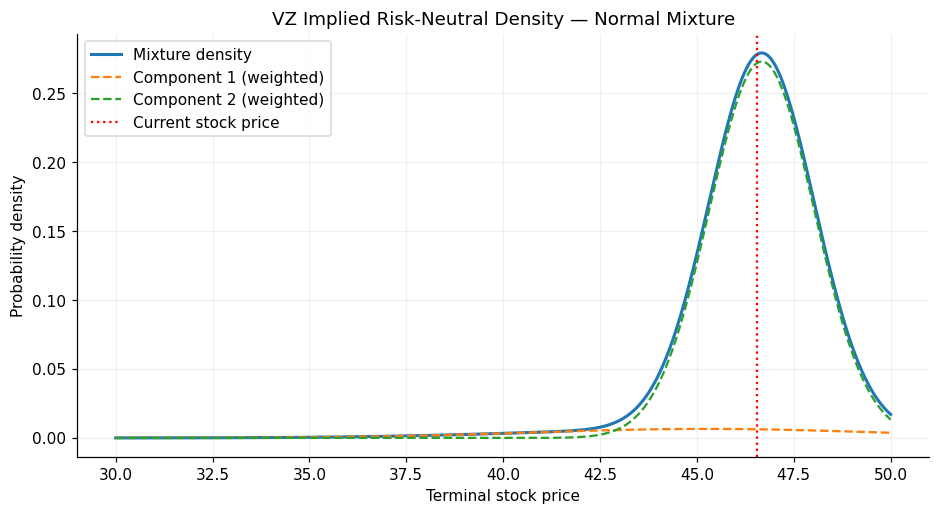

In [27]:
sigma_T1 = sigma1*np.sqrt(T)
sigma_T2 = sigma2*np.sqrt(T)

s = np.linspace(30, 50, 1000)

density1 = w * norm.pdf(s, mu1, sigma_T1)
density2 = (1-w) * norm.pdf(s, mu2, sigma_T2)

density_mix = density1 + density2

plt.figure(figsize=(10, 5))

plt.plot(s, density_mix, label="Mixture density", linewidth=2)
plt.plot(s, density1, "--", label="Component 1 (weighted)")
plt.plot(s, density2, "--", label="Component 2 (weighted)")

plt.axvline(S_0, color="red", linestyle=":", label="Current stock price")

plt.xlabel("Terminal stock price")
plt.ylabel("Probability density")
plt.title("VZ Implied Risk-Neutral Density — Normal Mixture")
plt.legend()
plt.grid(True)
plt.show()

Now we compare the two models, the lognormal one and the normal mixture and compare there results in the following table:

In [28]:
# table report
# Mean
mean_mix = w * mu1 + (1 - w) * mu2

# Variance and standard deviation
var_mix = (
    w * (sigma_T1**2 + (mu1 - mean_mix)**2)
    + (1-w) * (sigma_T2**2 + (mu2 - mean_mix)**2)
)

std_mix = np.sqrt(var_mix)

# Third central moment
m3 = (
    w * ((mu1 - mean_mix)**3
         + 3 * (mu1 - mean_mix) * sigma_T1**2)
    + (1-w) * ((mu2 - mean_mix)**3
               + 3 * (mu2 - mean_mix) * sigma_T2**2)
)

skew_mix = m3 / std_mix**3

# Probability of a 5% decline
threshold = 0.95 * S_0

prob_decline_mix = (
    w * norm.cdf(threshold, loc=mu1, scale=sigma_T1)
    + (1-w) * norm.cdf(threshold, loc=mu2, scale=sigma_T2)
)

# RMSE
rmse_mix = np.sqrt(np.mean((C_model - C_obs)**2))

# Get lognormal results from teammate's summary
log_summary = summary.set_index("Measure")["Value"]

# Normal mixture results
data_mix = [
    mean_mix,
    std_mix,
    skew_mix,
    prob_decline_mix,
    rmse_mix
]

# Lognormal results
data_log = [
    mean_ST,
    sd_ST,
    (np.exp(sigma_hat**2) + 2)
        * np.sqrt(np.expm1(sigma_hat**2)),
    norm.cdf(
        (np.log(0.95 * S0) - mu_hat) / sigma_hat
    ),
    chosen["rmse"]
]

measures = [
    "Mean terminal stock price",
    "Standard deviation",
    "Skewness",
    "Probability of a 5% price decline",
    "Root mean squared pricing error"
]

table_report = pd.DataFrame({
    "Measure": measures,
    "Lognormal": data_log,
    "Normal Mixture": data_mix
})

display(
    table_report.style.format({
        "Lognormal": "{:.6f}",
        "Normal Mixture": "{:.6f}"
    })
)

,Measure,Lognormal,Normal Mixture
0,Mean terminal stock price,46.567706,46.567706
1,Standard deviation,1.654633,1.825550
2,Skewness,0.106640,-0.912913
3,Probability of a 5% price decline,0.074932,0.062527
4,Root mean squared pricing error,0.038296,0.025003


From this information, The normal mixture seems to be fitting better as a distribution as the RMSE is aproximately 34.7% lower than the lognormal one. It also assigns a lower probability of a 5% percent decline. 
The skeweness of both distributions is very different, while the lognormal is skewed to the right, the normal mixture shows skeweness to the left, but this doesn't affect to the probability. 

### Part 4 — Independent Experiment (20 points)

We will select puts instead of calls and check for the differences in both models: lognormal and normal mixture. We will use the same assumptios for data cleaning as for the call prices so that the comparison is objective.

We start by cleaning again the data but now with puts instead of calls

In [29]:
eligible = quotes.loc[(quotes.option_type == 'put') & ##### Big change for put in this part :)
                      quotes.calendar_days.ge(MIN_CALENDAR_DAYS)].copy()
eligible['passes_rules'] = ~quality_flags(eligible).any(axis=1)
eligible['kept_strike'] = eligible.strike.where(eligible.passes_rules)
eligible['near_spot_kept'] = (eligible.passes_rules &
                             ((eligible.strike / eligible.spot_quote_mid - 1).abs() <= 0.05))
candidates = (eligible.groupby(['trade_date', 'expiry'], as_index=False)
    .agg(calendar_days=('calendar_days', 'first'), available_puts=('strike', 'size'),
         retained_by_rules=('passes_rules', 'sum'), near_spot_retained=('near_spot_kept', 'sum'),
         retained_K_min=('kept_strike', 'min'), retained_K_max=('kept_strike', 'max'),
         spot=('spot_quote_mid', 'median'))
    .sort_values(['retained_by_rules', 'near_spot_retained', 'trade_date'],
                 ascending=[False, False, True]).reset_index(drop=True))
if candidates.empty:
    raise ValueError('No eligible puts. Check the data and minimum calendar days.')
print(f'{len(candidates)} eligible date–expiration pairs. Top 15 under current rules:')
display(candidates.head(15).round(4))
print('Eligible calendar-day horizons:', sorted(eligible.calendar_days.unique().tolist()))

98 eligible date–expiration pairs. Top 15 under current rules:


,trade_date,expiry,calendar_days,available_puts,retained_by_rules,near_spot_retained,retained_K_min,retained_K_max,spot
0,2025-01-13,2025-01-17,4,43,25,6,37.0,60.0,38.055
1,2025-01-14,2025-01-17,3,43,25,6,37.5,60.0,38.275
2,2025-05-12,2025-05-16,4,42,24,6,41.5,65.0,42.975
3,2025-01-06,2025-01-10,4,39,20,7,38.0,53.0,39.625
4,2025-03-24,2025-03-28,4,40,19,7,42.5,54.0,43.615
5,2025-03-25,2025-03-28,3,40,19,6,42.5,55.0,43.395
6,2025-04-29,2025-05-02,3,41,19,5,42.0,56.0,42.945
7,2025-08-12,2025-08-15,3,41,19,4,43.0,60.0,43.225
8,2025-01-27,2025-01-31,4,40,18,6,40.0,55.0,40.645
9,2025-08-04,2025-08-08,4,39,18,5,42.0,55.0,42.955


Eligible calendar-day horizons: [3, 4]


In [30]:
trade_date, expiry = pd.Timestamp(SELECTED_DATE), pd.Timestamp(SELECTED_EXPIRY)
chain = quotes.loc[(quotes.trade_date == trade_date) & (quotes.expiry == expiry) &
                   (quotes.option_type == 'put')].sort_values('strike').copy()
if chain.empty:
    raise ValueError('Selected put chain is empty. Choose a pair from candidates.')
calendar_days = (expiry - trade_date).days
if calendar_days < MIN_CALENDAR_DAYS:
    raise ValueError('Selected expiration fails the minimum calendar-day requirement.')
if chain.strike.duplicated().any():
    raise ValueError('Duplicate strikes in this chain: review snapshots before proceeding.')

def checked_median(column):
    values = chain[column].replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        raise ValueError(f'No usable {column} in selected chain.')
    if values.max() - values.min() > 1e-8:
        warnings.warn(f'{column} differs across contracts: inspect its min/max before using the median.')
    return float(values.median())

S0 = checked_median('spot_quote_mid')
if S0 <= 0 or (chain.uAsk < chain.uBid).any() or (chain.uBid <= 0).any():
    raise ValueError('Invalid underlying quotes: review this chain.')
T_calendar = calendar_days / 365.0
T_vendor = checked_median('years')
if TIME_SOURCE not in {'calendar', 'vendor'}:
    raise ValueError("TIME_SOURCE must be 'calendar' or 'vendor'.")
T = T_calendar if TIME_SOURCE == 'calendar' else T_vendor
r = checked_median('rate') if RATE_OVERRIDE is None else float(RATE_OVERRIDE)
if not (np.isfinite(T) and T > 0 and np.isfinite(r)):
    raise ValueError('T must be positive and finite; r must be finite.')

input_columns = [c for c in ['uBid', 'uAsk', 'spot_quote_mid', 'uSrCls', 'uClose',
                             'rate', 'years', 'ddiv', 'sdiv'] if c in chain]
display(chain[input_columns].agg(['min', 'median', 'max']).T.round(8))
inputs = pd.DataFrame({
    'Input': ['Trading date', 'Expiration', 'Calendar days remaining', 'S0 (quote midpoint)',
              'T, ACT/365', 'T, vendor years', 'T used', 'Time source',
              'r used, annual decimal', 'r used, annual percent', 'Discount factor exp(-rT)'],
    'Value': [str(trade_date.date()), str(expiry.date()), calendar_days, S0,
              T_calendar, T_vendor, T, TIME_SOURCE, r, 100*r, np.exp(-r*T)]})
display(inputs)
print(f'Vendor T corresponds to {365*T_vendor:.4f} calendar-equivalent days; date difference is {calendar_days}.')
print('Rate convention:', RATE_NOTE)
print('All available strikes:', chain.strike.tolist())

,min,median,max
uBid,46.540000,46.540000,46.540000
uAsk,46.550000,46.550000,46.550000
spot_quote_mid,46.545000,46.545000,46.545000
uSrCls,46.545000,46.545000,46.545000
uClose,46.545000,46.545000,46.545000
rate,0.044504,0.044504,0.044504
years,0.014116,0.014116,0.014116
ddiv,0.000000,0.000000,0.000000
sdiv,-0.018376,-0.018376,-0.018376


,Input,Value
0,Trading date,2025-03-10
1,Expiration,2025-03-14
2,Calendar days remaining,4
3,S0 (quote midpoint),46.545
4,"T, ACT/365",0.010959
5,"T, vendor years",0.014116
6,T used,0.010959
7,Time source,calendar
8,"r used, annual decimal",0.044504
9,"r used, annual percent",4.45036


Vendor T corresponds to 5.1525 calendar-equivalent days; date difference is 4.
Rate convention: CSV rate; treated as annual continuously compounded, convention unverified
All available strikes: [25.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 39.5, 40.0, 40.5, 41.0, 41.5, 42.0, 42.5, 43.0, 43.5, 44.0, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 48.5, 49.0, 49.5, 50.0, 51.0, 52.0, 53.0, 55.0]


Now we plot the Puts as we plotted the Calls earlier

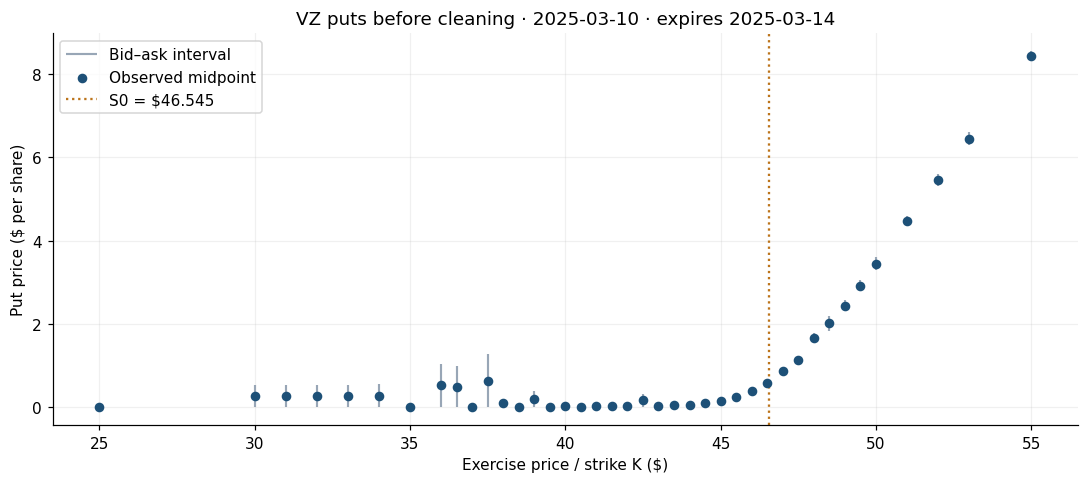

In [31]:
fig_raw, ax = plt.subplots(figsize=(10, 4.5))
plot_raw = chain.loc[np.isfinite(chain[['strike', 'bid', 'ask', 'mid']]).all(axis=1)]
ax.vlines(plot_raw.strike, plot_raw.bid, plot_raw.ask, color='#98a6b6', lw=1.4, label='Bid–ask interval')
ax.scatter(plot_raw.strike, plot_raw.mid, s=28, color='#1d5077', label='Observed midpoint', zorder=3)
ax.axvline(S0, color='#bc741b', ls=':', label=f'S0 = ${S0:.3f}')
ax.set(xlabel='Exercise price / strike K ($)', ylabel='Put price ($ per share)',
       title=f'VZ puts before cleaning · {trade_date.date()} · expires {expiry.date()}')
ax.legend(); fig_raw.tight_layout(); plt.show()

And apply our previously defined flags

In [32]:
flags = quality_flags(chain)
unknown_strikes = set(MANUAL_EXCLUSIONS) - set(chain.strike)
if unknown_strikes:
    raise ValueError(f'Manual exclusion strikes absent from chain: {unknown_strikes}')
if any(not isinstance(reason, str) or not reason.strip() for reason in MANUAL_EXCLUSIONS.values()):
    raise ValueError('Every manual exclusion must have a nonempty reason.')
manual_reason = chain.strike.map(MANUAL_EXCLUSIONS).fillna('')
chain['exclusion_reason'] = flags.apply(lambda row: '; '.join(row.index[row]), axis=1)
for idx in chain.index[manual_reason.ne('')]:
    existing = chain.at[idx, 'exclusion_reason']
    chain.at[idx, 'exclusion_reason'] = (existing + '; ' if existing else '') + 'manual: ' + manual_reason.at[idx]
chain['retained'] = chain.exclusion_reason.eq('')
clean = chain.loc[chain.retained].copy()
excluded = chain.loc[~chain.retained].copy()
if clean.empty:
    raise ValueError('No quotes survived. Review your selected date and thresholds.')
if len(clean) < 8:
    warnings.warn('Few retained strikes: estimating a flexible mixture may be unstable.')

audit_columns = ['source_row', 'strike', 'bid', 'ask', 'mid', 'spread', 'relative_spread',
                 'openInterest', 'prtVolume', 'retained', 'exclusion_reason']
audit_columns = [c for c in audit_columns if c in chain]
audit = chain[audit_columns].copy()
rule_counts = flags.sum().rename('Quotes failing rule').to_frame()
rule_counts.loc['manual exclusion'] = int(manual_reason.ne('').sum())
display(rule_counts)
print(f'Retained {len(clean)} of {len(chain)} puts; excluded {len(excluded)}.')
print('Retained strikes:', clean.strike.tolist())
display(audit.round({'mid': 4, 'spread': 4, 'relative_spread': 4}))

,Quotes failing rule
nonfinite strike/bid/ask,0
nonpositive strike,0
negative bid or ask,0
crossed market (ask < bid),0
zero bid,19
midpoint below minimum,11
absolute spread above limit,11
relative spread above limit,21
manual exclusion,0


Retained 17 of 40 puts; excluded 23.
Retained strikes: [43.5, 44.0, 44.5, 45.0, 45.5, 46.0, 46.5, 47.0, 47.5, 48.0, 49.0, 49.5, 50.0, 51.0, 52.0, 53.0, 55.0]


,source_row,strike,bid,ask,mid,spread,relative_spread,openInterest,prtVolume,retained,exclusion_reason
3564,3566,25.0,0.00,0.01,0.005,0.01,2.0000,0,0,False,zero bid; midpoint below minimum; relative spr...
3566,3568,30.0,0.00,0.53,0.265,0.53,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3568,3570,31.0,0.00,0.53,0.265,0.53,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3570,3572,32.0,0.00,0.54,0.270,0.54,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3572,3574,33.0,0.00,0.54,0.270,0.54,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3574,3576,34.0,0.00,0.56,0.280,0.56,2.0000,0,0,False,zero bid; absolute spread above limit; relativ...
3576,3578,35.0,0.00,0.02,0.010,0.02,2.0000,1,0,False,zero bid; midpoint below minimum; relative spr...
3578,3580,36.0,0.00,1.05,0.525,1.05,2.0000,62,0,False,zero bid; absolute spread above limit; relativ...
3580,3582,36.5,0.00,0.99,0.495,0.99,2.0000,1,0,False,zero bid; absolute spread above limit; relativ...
3582,3584,37.0,0.00,0.02,0.010,0.02,2.0000,97,0,False,zero bid; midpoint below minimum; relative spr...


Now we visaluize both the data we discarded and the one we kept

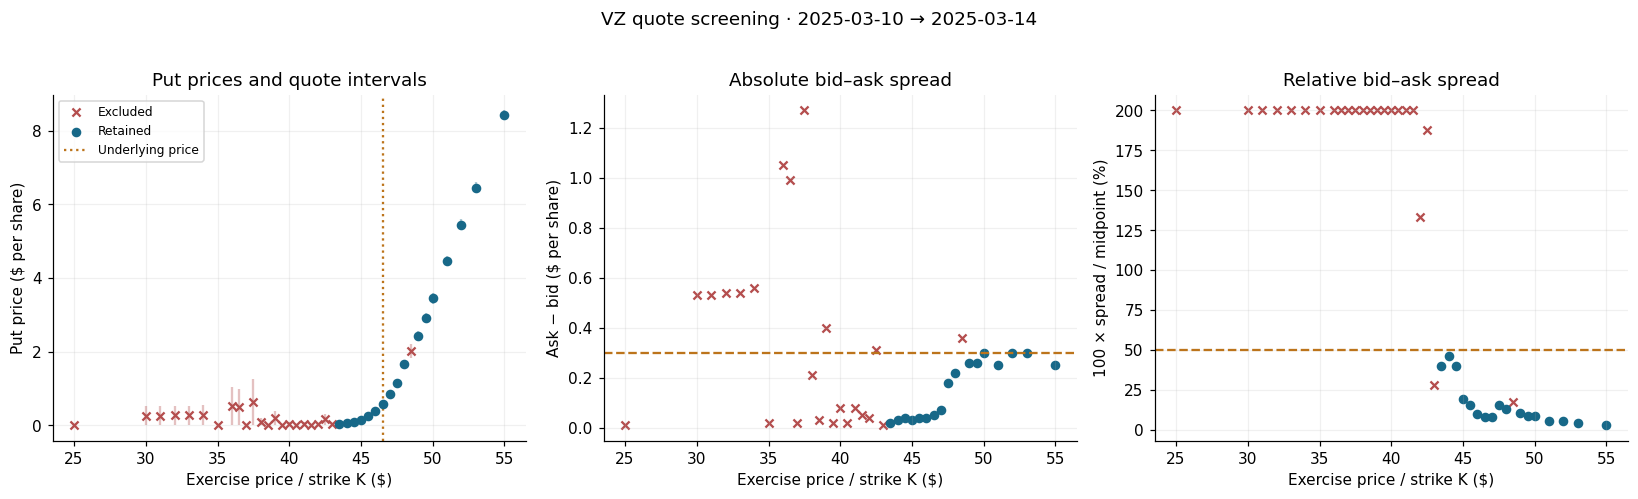

In [33]:
fig_clean, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for keep, label, color, marker in [(False, 'Excluded', '#b44e4e', 'x'),
                                  (True, 'Retained', '#176888', 'o')]:
    d = chain.loc[chain.retained.eq(keep)]
    axes[0].vlines(d.strike, d.bid, d.ask, color=color, alpha=0.35)
    axes[0].scatter(d.strike, d.mid, c=color, marker=marker, s=28, label=label, zorder=3)
    axes[1].scatter(d.strike, d.spread, c=color, marker=marker, s=28)
    axes[2].scatter(d.strike, 100*d.relative_spread, c=color, marker=marker, s=28)
axes[0].axvline(S0, color='#bc741b', ls=':', label='Underlying price')
axes[0].set(title='Put prices and quote intervals', ylabel='Put price ($ per share)')
axes[0].legend(fontsize=8)
axes[1].axhline(MAX_ABS_SPREAD, color='#bc741b', ls='--', label='Absolute cutoff')
axes[1].set(title='Absolute bid–ask spread', ylabel='Ask − bid ($ per share)')
axes[2].axhline(100*MAX_REL_SPREAD, color='#bc741b', ls='--', label='Relative cutoff')
axes[2].set(title='Relative bid–ask spread', ylabel='100 × spread / midpoint (%)')
for ax in axes:
    ax.set_xlabel('Exercise price / strike K ($)')
fig_clean.suptitle(f'VZ quote screening · {trade_date.date()} → {expiry.date()}', y=1.02)
fig_clean.tight_layout(); plt.show()

Just by this graph and the previous results, we can see that more puts were excluded than calls. This could change drastically our results and distributions as it seems it is discarding the tails.

We now save the put data

In [34]:
calibration_data = clean[['trade_date', 'expiry', 'strike', 'bid', 'ask', 'mid',
                          'spread', 'relative_spread', 'source_row']].copy()
calibration_data['S0'] = S0
calibration_data['T'] = T
calibration_data['r'] = r
K = calibration_data.strike.to_numpy(dtype=float)
C_obs = calibration_data.mid.to_numpy(dtype=float)

metadata = {
    'source_file': CSV_PATH.name, 'source_sha256': file_sha256,
    'trade_date': str(trade_date.date()), 'expiry': str(expiry.date()),
    'calendar_days': calendar_days, 'S0': S0, 'spot_source': '(uBid + uAsk) / 2',
    'T': T, 'time_source': TIME_SOURCE, 'T_calendar': T_calendar, 'T_vendor': T_vendor,
    'r': r, 'rate_note': RATE_NOTE, 'rate_override': RATE_OVERRIDE,
    'dividend_assumption': 'Unresolved: verify schedule and CSV field conventions before fitting',
    'price_source': '(bidPrc + askPrc) / 2',
    'min_mid': MIN_MID, 'max_absolute_spread': MAX_ABS_SPREAD,
    'max_relative_spread': MAX_REL_SPREAD,
    'manual_exclusions': {str(k): v for k, v in MANUAL_EXCLUSIONS.items()},
    'available_puts': len(chain), 'retained_puts': len(clean),
    'strike_min': float(K.min()), 'strike_max': float(K.max()),
}
assert calibration_data.strike.is_unique
assert np.isfinite(calibration_data[['strike','bid','ask','mid','S0','T','r']]).all().all()
assert (calibration_data.ask >= calibration_data.bid - EPS).all()
display(calibration_data.round(6))
if EXPORT_FILES:
    out = Path('part4_outputs')
    out.mkdir(exist_ok=True)
    calibration_data.to_csv(out / 'VZ_part4_clean_puts.csv', index=False)
    audit.to_csv(out / 'VZ_part4_quote_audit.csv', index=False)
    candidates.to_csv(out / 'VZ_part4_candidates.csv', index=False)
    (out / 'VZ_part4_inputs.json').write_text(json.dumps(metadata, indent=2))
    fig_raw.savefig(out / 'VZ_part4_observed_puts.png', dpi=180, bbox_inches='tight')
    fig_clean.savefig(out / 'VZ_part4_screening.png', dpi=180, bbox_inches='tight')
    print('Exported tables, assumptions and plots to', out.resolve())
else:
    print('Exports disabled; all tables and plots remain visible in this notebook.')

,trade_date,expiry,strike,bid,ask,mid,spread,relative_spread,source_row,S0,T,r
3608,2025-03-10,2025-03-14,43.5,0.04,0.06,0.050,0.02,0.400000,3610,46.545,0.010959,0.044504
3610,2025-03-10,2025-03-14,44.0,0.05,0.08,0.065,0.03,0.461538,3612,46.545,0.010959,0.044504
3612,2025-03-10,2025-03-14,44.5,0.08,0.12,0.100,0.04,0.400000,3614,46.545,0.010959,0.044504
3614,2025-03-10,2025-03-14,45.0,0.14,0.17,0.155,0.03,0.193548,3616,46.545,0.010959,0.044504
3616,2025-03-10,2025-03-14,45.5,0.23,0.27,0.250,0.04,0.160000,3618,46.545,0.010959,0.044504
3618,2025-03-10,2025-03-14,46.0,0.37,0.41,0.390,0.04,0.102564,3620,46.545,0.010959,0.044504
3620,2025-03-10,2025-03-14,46.5,0.57,0.62,0.595,0.05,0.084034,3622,46.545,0.010959,0.044504
3622,2025-03-10,2025-03-14,47.0,0.83,0.90,0.865,0.07,0.080925,3624,46.545,0.010959,0.044504
3624,2025-03-10,2025-03-14,47.5,1.05,1.23,1.140,0.18,0.157895,3626,46.545,0.010959,0.044504
3626,2025-03-10,2025-03-14,48.0,1.56,1.78,1.670,0.22,0.131737,3628,46.545,0.010959,0.044504


Exported tables, assumptions and plots to C:\Users\samla\OneDrive\Documentos 1\Documentos\ELAB\Maestría\NYU\Semester 1\Valuation for Financial Engineering\Homework\Mini Project 5\miniProject5\part4_outputs


### 4.2 Lognormal model for puts
Now that we have our porcessed put data ready, we will make the a new lognormal distribution adapting the past functions for puts instead of calls. Now the function Put price equation is: 

$$
P = e^{-rT}[K\Phi(-d_2)- F \Phi(-d_1)]
$$

First we retrieve the dataframe

In [35]:
PROCESSED_DIR_PUT = PROJECT_ROOT / 'part4_outputs' 
cal_data_put = pd.read_csv(PROCESSED_DIR_PUT / 'VZ_part4_clean_puts.csv')

T_p = cal_data_put['T'].iloc[0]
r_p = cal_data_put['r'].iloc[0]
S_0_p = cal_data_put['S0'].iloc[0]
K_p = cal_data_put.strike.to_numpy(dtype=float)
P_obs = cal_data_put.mid.to_numpy(dtype=float)
bid_obs = cal_data_put.bid.to_numpy(dtype=float)
ask_obs = cal_data_put.ask.to_numpy(dtype=float)
if len(K_p) < 3 or np.any(K_p <= 0):
    raise ValueError('Need at least three positive, distinct strikes for this calibration and its diagnostics.')
discount_p = np.exp(-r_p*T_p)
F_carry_p = (S_0_p-pv_dividends)*np.exp(r_p*T_p)

In [36]:
def lognormal_put_from_mean(strikes, F, sigma, rate, maturity):
    """European put prices from terminal mean F and terminal log-SD sigma."""

    strikes = np.asarray(strikes, dtype=float)

    if np.any(strikes <= 0) or F <= 0 or sigma <= 0:
        raise ValueError(
            "Strikes, F and terminal sigma must be positive."
        )

    d2 = (np.log(F / strikes) - 0.5 * sigma**2) / sigma
    d1 = d2 + sigma

    return np.exp(-rate * maturity) * (
        strikes * norm.cdf(-d2)
        - F * norm.cdf(-d1)
    )

def lognormal_put(strikes, mu, sigma, rate, maturity):
    F = np.exp(mu + 0.5 * sigma**2)
    return lognormal_put_from_mean(strikes, F, sigma, rate, maturity)


In [37]:

SIGMA_BOUNDS = (1e-5, 2.0)
F_BOUNDS = (0.1 * S_0_p, 10 * S_0_p)

sigma_initial = np.clip(
    0.25 * np.sqrt(T_p),
    1e-4,
    1.0
)

def fit_lognormal_put(mean_treatment):

    if mean_treatment == "forward":

        x0 = [np.log(sigma_initial)]

        bounds = (
            [np.log(SIGMA_BOUNDS[0])],
            [np.log(SIGMA_BOUNDS[1])]
        )

        def unpack(x):
            return F_carry_p, float(np.exp(x[0]))

    elif mean_treatment == "free":

        x0 = [
            np.log(F_carry_p),
            np.log(sigma_initial)
        ]

        bounds = (
            np.log([F_BOUNDS[0], SIGMA_BOUNDS[0]]),
            np.log([F_BOUNDS[1], SIGMA_BOUNDS[1]])
        )

        def unpack(x):
            return float(np.exp(x[0])), float(np.exp(x[1]))

    else:
        raise ValueError("Unknown mean treatment")

    # Pricing residuals
    def residual(x):

        F, sigma = unpack(x)

        model_prices = lognormal_put_from_mean(
            K_p, F, sigma, r_p, T_p
        )

        return model_prices - P_obs

    # Analytical Jacobian
    def jacobian(x):

        F, sigma = unpack(x)

        d1 = (
            np.log(F / K_p) + 0.5 * sigma**2
        ) / sigma

        d_logF = (
            -discount_p * F * norm.cdf(-d1)
        )

        d_logsigma = (
            discount_p * F * norm.pdf(d1) * sigma
        )

        if mean_treatment == "forward":
            return d_logsigma[:, None]

        return np.column_stack([d_logF, d_logsigma])

    # Optimization
    result = least_squares(
        residual,
        x0,
        jac=jacobian,
        bounds=bounds,
        loss="linear",
        ftol=1e-12,
        xtol=1e-12,
        gtol=1e-12,
        max_nfev=3000
    )

    if not result.success:
        raise RuntimeError(result.message)

    # Recover parameters
    F, sigma = unpack(result.x)

    mu = np.log(F) - 0.5 * sigma**2

    fitted_prices = lognormal_put_from_mean(
        K_p, F, sigma, r_p, T_p
    )

    rmse = np.sqrt(
        np.mean((fitted_prices - P_obs)**2)
    )

    return {
        "mean_treatment": mean_treatment,
        "F": F,
        "mu": mu,
        "sigma": sigma,
        "rmse": rmse,
        "fitted": fitted_prices,
        "optimizer": result
    }


Now we execute the calibration

In [38]:
fits_put = {
    mode: fit_lognormal_put(mode)
    for mode in ["forward", "free"]
}

for mode, fit in fits_put.items():
    print(f"\n{mode.upper()}")
    print("F:", fit["F"])
    print("mu:", fit["mu"])
    print("sigma:", fit["sigma"])
    print("RMSE:", fit["rmse"])
    print("Success:", fit["optimizer"].success)


FORWARD
F: 46.56770603036687
mu: 3.840319693302811
sigma: 0.03428130541777652
RMSE: 0.0348384559148432
Success: True

FREE
F: 46.56422171547616
mu: 3.8402491037481643
sigma: 0.03415752179999814
RMSE: 0.03477281337162197
Success: True


The put-based lognormal calibration produces nearly identical results under the forward-constrained and unrestricted specifications. The unrestricted model estimates a terminal mean of $46.5642, very close to the carry-implied forward price of $46.5677.

Furthermore, allowing the mean to vary reduces the pricing RMSE only marginally, from $0.03484 to $0.03477 per share. This suggests that relaxing the forward constraint provides little additional explanatory power for the selected put prices.

However, this result does not establish that the inferred distribution is uniquely identified or that the European pricing approximation fully captures the observed American put prices.

Now we will first make the normal mixture calibration to discuss even firther the best model

---

### 4.2 Normal Mixture for Puts

For the normal mixture, we first need to define a new function for pricing puts using Bachelier:

$$
P_i = \Beta(K - \mu_i) \Phi(-d) + \Beta \sigma \sqrt{T} \phi(d)  \\
\text{where } \\
d = \frac{\mu_i - K}{\sigma\sqrt{T}} \\
and \\
\Beta = e^{-rT}
$$

And we aslso need to define new functions: `bach_put`, `mix_put` and `optim_fun_put`

In [39]:
def bach_put(r, mu, K, sigma, T):

    B = np.exp(-r*T)
    d = (mu-K)/(sigma*np.sqrt(T))

    c_price = B*(K-mu)*norm.cdf(-d) + B*sigma*np.sqrt(T)*norm.pdf(d)

    return c_price

def mix_put(K, theta, r, T):
    mu1, sigma1, mu2, sigma2, w = theta

    call_mix = w* bach_put(r, mu1, K, sigma1, T) + (1-w)*bach_put(r, mu2, K, sigma2, T)
    return call_mix

def optim_fun_put(theta, K, C_obs, r, T):
    C_model = mix_put(K, theta, r, T)
    return np.sum((C_model - C_obs)**2)

And we optimize following the next random initial parameters for the puts

- $\mu_1 \sim Unif(S_0 - 2, S_0)$
- $\sigma_1 \sim Unif(0.3, 2)$
- $\mu_2 \sim Unif(S_0, S_0+2)$
- $\sigma_2 \sim Unif(0.3, 2)$
- $w \sim Unif(0.2,0.8)$

With the following bounds:
- $\sigma_1 > 0$
- $\sigma_2 > 0$
- $0 \leq w \leq 1$

In [40]:
rand_seed = 123

np.random.seed(rand_seed)
theta_ini_put = (
    np.random.uniform(S_0_p - 2, S_0_p),
    np.random.uniform(0.3, 2),
    np.random.uniform(S_0_p, S_0_p + 2),
    np.random.uniform(0.3, 2),
    np.random.uniform(0.2, 0.8)
)

bounds = [
    (None, None),  # mu1
    (1e-6, None),  # sigma1 > 0
    (None, None),  # mu2
    (1e-6, None),  # sigma2 > 0
    (0, 1)         # 0 <= w <= 1
]
res_put = minimize(optim_fun_put, theta_ini_put, args= (K_p, P_obs, r_p, T_p), method="L-BFGS-B", bounds=bounds)

In [41]:
print("Success:", res_put.success)
print("Message:", res_put.message)
print("Parameters:", res_put.x)
print("Objective:", res_put.fun)

Success: True
Message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Parameters: [44.11049747  2.7157649  46.5616265  15.1608689   0.        ]
Objective: 0.018711411440428843


As well as in the Call normal mixture, we also need to try the Froward calibration. for this we need to adapt our calibration function

In [42]:
def calibrate_mixture_put(K, P_obs, r, T, S0, F_carry=None,
                            n_starts=100, seed=123):

    rng = np.random.default_rng(seed)

    bounds = [
        (None, None),  # mu1
        (1e-6, None),  # sigma1
        (None, None),  # mu2
        (1e-6, None),  # sigma2
        (0, 1)         # w
    ]

    constraints = []

    if F_carry is not None:

        def forward_constraint(theta):
            mu1, sigma1, mu2, sigma2, w = theta
            return w*mu1 + (1-w)*mu2 - F_carry

        constraints = [
            {"type": "eq", "fun": forward_constraint}
        ]

    results = []

    for i in range(n_starts):

        theta0 = np.array([
            rng.uniform(S0 - 2, S0),
            rng.uniform(0.3, 20),
            rng.uniform(S0, S0 + 2),
            rng.uniform(0.3, 20),
            rng.uniform(0.1, 0.9)
        ])

        # For constrained optimization, make the
        # starting point satisfy the forward mean.
        if F_carry is not None:
            w0 = theta0[4]
            theta0[2] = (
                F_carry - w0 * theta0[0]
            ) / (1 - w0)

        result = minimize(
            optim_fun_put,
            theta0,
            args=(K, P_obs, r, T),
            method="SLSQP" if F_carry is not None else "L-BFGS-B",
            bounds=bounds,
            constraints=constraints,
            options=(
                {"maxiter": 3000, "ftol": 1e-10}
                if F_carry is not None
                else {"maxiter": 3000, "ftol": 1e-12}
            )
        )

        if result.success and np.isfinite(result.fun):
            if F_carry is None or abs(
                forward_constraint(result.x)
            ) < 1e-6:
                results.append(result)

    if not results:
        raise RuntimeError("No successful calibrations.")

    best = min(results, key=lambda x: x.fun)

    rmse = np.sqrt(best.fun / len(C_obs))

    return best, rmse, results

In [43]:
# Free mixture calibrated to puts
best_free_put, rmse_free_put, results_free_put = calibrate_mixture_put(
    K_p, P_obs, r_p, T_p, S_0_p,
    F_carry=None,
    n_starts=100,
    seed=123
)

# Forward-constrained mixture calibrated to puts
best_forward_put, rmse_forward_put, results_forward_put = calibrate_mixture_put(
    K_p, P_obs, r_p, T_p, S_0_p,
    F_carry=F_carry_p,
    n_starts=100,
    seed=123
)

print("FREE PUT MIXTURE")
print("Parameters:", best_free_put.x)
print("RMSE:", rmse_free_put)

print("\nFORWARD PUT MIXTURE")
print("Parameters:", best_forward_put.x)
print("RMSE:", rmse_forward_put)

print("\nSuccessful free runs:", len(results_free_put))
print("Successful forward runs:", len(results_forward_put))

FREE PUT MIXTURE
Parameters: [3.90514129e+01 1.93472880e+01 4.66238124e+01 1.41663673e+01
 8.96102828e-03]
RMSE: 0.0294277359808819

FORWARD PUT MIXTURE
Parameters: [ 4.65987607e+01  1.43571055e+01 -1.49875666e+02  3.59675808e+03
  9.99841941e-01]
RMSE: 0.029462224008898856

Successful free runs: 100
Successful forward runs: 92


Now lets plot the forward for comparison

In [44]:
mu1_p, sigma1_p, mu2_p, sigma2_p, w_p = best_forward_put.x

P_model = mix_put(K_p, best_forward_put.x, r_p, T_p)

rmse_p = np.sqrt(np.mean((P_model - P_obs)**2))

print("RMSE:", rmse_p)
print("Mixture mean:", w_p*mu1_p + (1-w_p)*mu2_p)

RMSE: 0.029462224008898856
Mixture mean: 46.56770603036588


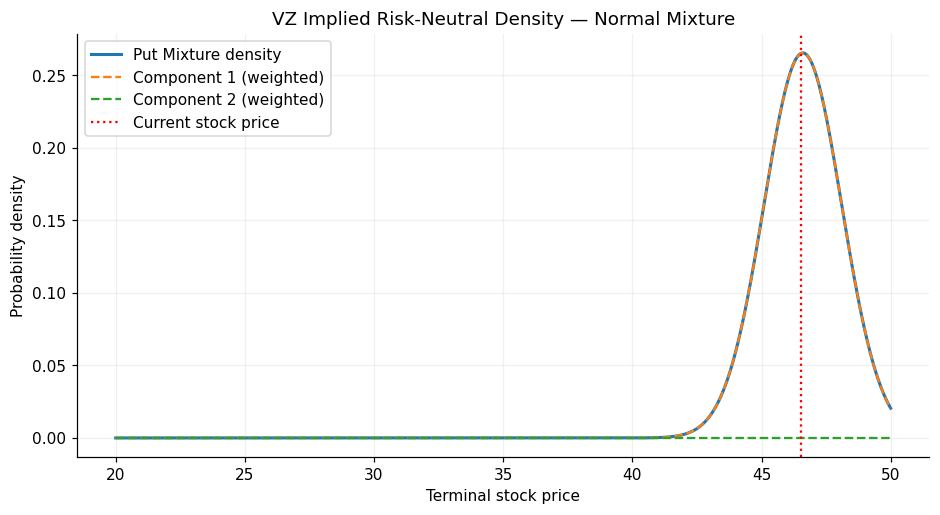

In [45]:
sigma_T1_p = sigma1_p*np.sqrt(T_p)
sigma_T2_p = sigma2_p*np.sqrt(T_p)

s = np.linspace(20, 50, 1000)

density1_p = w_p * norm.pdf(s, mu1_p, sigma_T1_p)
density2_p = (1-w_p) * norm.pdf(s, mu2_p, sigma_T2_p)

density_mix_p = density1_p + density2_p

plt.figure(figsize=(10, 5))

plt.plot(s, density_mix_p, label="Put Mixture density", linewidth=2)
plt.plot(s, density1_p, "--", label="Component 1 (weighted)")
plt.plot(s, density2_p, "--", label="Component 2 (weighted)")

plt.axvline(S_0_p, color="red", linestyle=":", label="Current stock price")

plt.xlabel("Terminal stock price")
plt.ylabel("Probability density")
plt.title("VZ Implied Risk-Neutral Density — Normal Mixture")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
# Mean
mean_mix_p = w_p * mu1_p + (1 - w_p) * mu2_p

# Variance and standard deviation
var_mix_p = (
    w_p * (sigma_T1_p**2 + (mu1_p - mean_mix_p)**2)
    + (1-w_p) * (sigma_T2_p**2 + (mu2_p - mean_mix_p)**2)
)

std_mix_p = np.sqrt(var_mix_p)

# Third central moment
m3_p = (
    w_p * ((mu1_p - mean_mix_p)**3
         + 3 * (mu1_p - mean_mix_p) * sigma_T1_p**2)
    + (1-w_p) * ((mu2_p - mean_mix_p)**3
               + 3 * (mu2_p - mean_mix_p) * sigma_T2_p**2)
)

skew_mix_p = m3_p / std_mix_p**3

# Probability of a 5% decline
threshold_p = 0.95 * S_0_p

prob_decline_mix_p = (
    w_p * norm.cdf(threshold_p, loc=mu1_p, scale=sigma_T1_p)
    + (1-w_p) * norm.cdf(threshold_p, loc=mu2_p, scale=sigma_T2_p)
)

# RMSE
rmse_mix_p = np.sqrt(np.mean((P_model - P_obs)**2))


# Select forward-constrained lognormal fitted to puts
log_fit_p = fits_put["forward"]

# Lognormal parameters
mu_log_p = log_fit_p["mu"]
sigma_log_p = log_fit_p["sigma"]

# Lognormal statistics
mean_log_p = log_fit_p["F"]

std_log_p = mean_log_p * np.sqrt(
    np.expm1(sigma_log_p**2)
)

skew_log_p = (
    (np.exp(sigma_log_p**2) + 2)
    * np.sqrt(np.expm1(sigma_log_p**2))
)

prob_decline_log_p = norm.cdf(
    (np.log(0.95 * S_0_p) - mu_log_p) / sigma_log_p
)

rmse_log_p = log_fit_p["rmse"]

# Compare against your already computed mixture statistics
table_report_p = pd.DataFrame({
    "Measure": [
        "Mean terminal stock price",
        "Standard deviation",
        "Skewness",
        "Probability of a 5% price decline",
        "Root mean squared pricing error"
    ],
    "Lognormal (Puts)": [
        mean_log_p,
        std_log_p,
        skew_log_p,
        prob_decline_log_p,
        rmse_log_p
    ],
    "Normal Mixture (Puts)": [
        mean_mix_p,
        std_mix_p,
        skew_mix_p,
        prob_decline_mix_p,
        rmse_mix_p
    ]
})

display(table_report_p.round(6))


,Measure,Lognormal (Puts),Normal Mixture (Puts)
0,Mean terminal stock price,46.567706,46.567706
1,Standard deviation,1.596871,5.546836
2,Skewness,0.102914,-84.400405
3,Probability of a 5% price decline,0.067675,0.056675
4,Root mean squared pricing error,0.034838,0.029462


The put-based lognormal model produces a more economically plausible distribution, with a standard deviation of 1.60 and a skewness of 0.10. In contrast, the normal mixture exhibits an extremely negative skewness of −84.40 and a standard deviation of 5.55, mainly driven by its second component, which has a mean of approximately −$149.88 and a very large variance.

Although the normal mixture achieves a lower pricing RMSE ($0.02946 versus $0.03484), it estimates a slightly lower probability of a 5% price decline (5.67% versus 6.77%). However, the lower pricing error does not necessarily imply more reliable tail probability estimates.

These results suggest that the additional flexibility of the normal mixture may lead to unstable or economically implausible parameter estimates, particularly when the available option prices provide limited information about extreme outcomes.